<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QVC_AdversarialBenchmark_West2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Benchmarking adversarially robust quantum variational classifiers (West et al., 2023) step by step

This notebook re-implements, runs and checks the experiments of

> Maxwell T. West, Sarah M. Erfani, Christopher Leckie, Martin Sevior, Lloyd C. L. Hollenberg and Muhammad Usman,
> "Benchmarking Adversarially Robust Quantum Machine Learning at Scale",
> *Physical Review Research* **5**, 023186 (2023), arXiv:2211.12681. https://doi.org/10.1103/PhysRevResearch.5.023186

**What it does.** A quantum variational classifier (QVC) loads an image into the amplitudes of a 10-qubit state (amplitude encoding), applies many layers of
single-qubit rotations and nearest-neighbour CZ gates and reads the class from Pauli-Z expectation values. The paper attacks such QVCs and two classical
networks (a ConvNet and a ResNet-18) with adversarial images (PGD, FGSM, AutoAttack) and reports four things: (i) adversarial images computed on a *classical* network
transfer poorly to the QVC, (ii) images computed on the QVC *do* fool classical networks, (iii) adversarial training helps the QVC much less than a classical network, and
(iv) a "disagreement detector" (classical network and QVC predict different labels) can flag attacked images.
The notebook reproduces each of these on real MNIST and Fashion-MNIST images, with a PyTorch state-vector simulator that is checked against the real PennyLane QNode and a Qiskit circuit.
**It also adds what the paper does not do:** controls (random noise, low-capacity classical models), a query-only imitation attack, and an *adaptive white-box attack on the QVC itself*
(and on the detector) to test whether the reported robustness is real or an artefact of weak attacks.

**How to run.** Open in Colab, choose a **CPU** runtime, then *Runtime -> Run all*. `FAST_MODE = True` (configuration cell) is a class demo. **The committed outputs are from the FAST run, which took 54 minutes on one thread of a CPU shared with about 14 other jobs** (the ResNet-18 training alone took 8-10 minutes per data set); on an idle laptop or a Colab CPU runtime expect roughly 15-30 minutes (estimate, not measured). `FAST_MODE = False` uses larger budgets (documented in the configuration cell) that were estimated at several hours and were **not run** for this notebook. Everything is simulated exactly; no quantum hardware and no account are needed (`IBM_TOKEN` stays empty).

**What you get at the end.** Real image visualisations, drawings of the executed circuits, clean accuracies of the QVCs, a ConvNet, a ResNet-18 and classical baselines,
the transfer/defence curves of the paper's Fig. 2, the perturbation analysis of Fig. 3, adversarial training (Fig. 4), the attack detector (Fig. 5), a bit-flip noise check (Fig. S14),
an adaptive-attack audit, and a table with a verdict per claim of the paper.

## The paper in one page

**Problem.** Quantum machine learning (QML) models can be fooled by adversarial examples, but earlier studies used tiny, down-scaled problems and white-box attacks only. The paper benchmarks
QVCs "at scale": full 28 x 28 MNIST and Fashion-MNIST (all ten classes; 10 qubits), CIFAR-10 (ships vs trucks) and Celeb-A (black hair, binary; 12 qubits).

**Encoding.** Amplitude encoding (Eq. 3): `|psi(x)> = sum_i x_i |i> / ||x||`, zero padded from 784 to 1 024 amplitudes = 10 qubits. (The images are real, so the amplitudes are real.)

**Classifier.** `L` layers, each a parametrised rotation on every qubit followed by nearest-neighbour CZ gates (39 gates per layer on 10 qubits: 30 rotations + 9 CZ). QVC200 / QVC500 / QVC1000 have 200 / 500 / 1000 layers
and 6 000 / 15 000 / 30 000 parameters (3 per qubit and layer). Prediction: argmax of the Pauli-Z expectation values of the first `m` qubits (`m` = number of classes). Adam + cross-entropy, PennyLane.

**Classical networks.** ConvNet (three 3x3 conv layers with 64, 128, 256 maps, 2x2 max-pooling, ReLU, two FC layers, about 10^6 parameters) and ResNet-18 (about 10^7 parameters), PyTorch, Adam.

**Attacks.** l-infinity PGD, FGSM and AutoAttack with strength `eps`; white-box attacks on ConvNet, ResNet and QVC200, applied to the *other* networks to measure *transferability* (same family)
and *defence* (across the classical/quantum boundary). 250 attacked test images per data set. Adversarial training: 50 % clean + 50 % PGD (3 steps) images, `eps` = 0.1, 0.2, 0.3.

**Claims reproduced here.**
(C1) ConvNet to ResNet attacks transfer (classical to classical). (C2) QVC200 resists ConvNet attacks "retaining reasonable accuracies even for eps >= 0.2". (C3) The QVC is vulnerable to white-box attacks.
(C4) QVC200 attacks transfer to the deeper QVC, but more weakly than classical to classical. (C5) QVC attacks fool the classical networks (one-way asymmetry together with C2).
(C6) QVC perturbations contain visible semantic structure, classical ones look like noise. (C7) Adversarial training barely changes the QVC's accuracy against classical attacks, improves it against QVC attacks (white box on the standard QVC) and does not reduce clean accuracy; it helps the ConvNet a lot.
(C8) Deeper QVCs do not change accuracy or robustness much (Fig. S2, S15). (C9) Detector: Fashion-MNIST, ConvNet vs QVC500: 227 false and 736 true positives out of 1 000 + 1 000; ResNet vs QVC500: 234 and 795.
(C10) Noise (Fig. S14): depolarising noise does not change the accuracy, bit flips (0.5 %) reduce it slightly, amplitude damping destroys it.

### What follows the paper and what had to be chosen

The paper's results are accuracy curves in figures (no tables) and its code is not provided with the arXiv version, so the checks compare **qualitative claims and the few printed numbers** (the detector counts).
Everything the text does not fix is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data sets | MNIST, Fashion-MNIST (full 60 000 training images), CIFAR-10 ships/trucks, Celeb-A black hair | MNIST and Fashion-MNIST from Hugging Face (`ylecun/mnist`, `zalando-datasets/fashion_mnist`). **CIFAR-10 and Celeb-A are not used**: the only Hugging Face mirrors are single parquet files of 100 MB to several GB (CIFAR-10 train is about 120 MB, Celeb-A over 1 GB), which exceed the size limit for this notebook; the 12-qubit experiments are therefore *not reproduced* |
| Training set | all training images | class-balanced random subset (1 000 images in `FAST_MODE`, 2 500 otherwise) for **all** models, quantum and classical (identical inputs); a CPU cannot train a 10-qubit, deep QVC on 60 000 images in minutes |
| Qubits / encoding | 10 qubits, amplitude encoding of 784 pixels, zero padded | identical (real amplitudes, Eq. 3) |
| QVC depth | QVC200, QVC500, QVC1000 | **QVC-A** with 10 layers (`FAST_MODE`) or 20 layers, **QVC-B** with twice as many (stand-ins for QVC200 / QVC500); simulation cost grows linearly with depth. Parameters: `3 * 10 * L` (300 / 600 / 600 / 1 200) |
| Rotations | "parametrised rotation to each qubit" (30 rotation gates per layer: RX, RY, RZ) | `qml.Rot` = RZ RY RZ with three angles per qubit (the same 3 parameters per qubit and layer, 30 rotation gates per layer) |
| Read-out | Z expectation values of the first `m` qubits (Eq. 4) | identical (`m` = 10); logits = `LOGIT_SCALE` x expectation values before the softmax (CHOICE: expectation values lie in [-1, 1], an unscaled softmax trains very slowly; the scale does not change the prediction) |
| Optimiser | Adam, cross-entropy, learning rate not given | Adam with a one-cycle learning-rate schedule, peak 0.1 (CHOICE, pilot run on a validation subset of the training split); initial angles N(0, 1) |
| ConvNet | 3 conv layers (64, 128, 256 maps), 2 FC layers, ~10^6 parameters | same layout with 16, 32, 64 maps (CHOICE: CPU) |
| ResNet-18 | standard | standard layout (4 stages x 2 basic blocks), base width 16 instead of 64 (CHOICE: CPU), one input channel |
| Attacks | PGD, FGSM, AutoAttack; step number of the evaluation attacks not given; adversarial training with 3 PGD steps | PGD (random start, `PGD_STEPS` steps of size 2.5 eps / steps, l-inf, clip to [0, 1]) and FGSM. **AutoAttack is not run** (it needs the external `autoattack` package; the multi-restart margin-loss PGD of the adaptive section is the strong attack used instead) |
| Attacked images | 250 test images per data set | first `N_ATK` images of the test subset (150 in `FAST_MODE`, 250 otherwise) |
| Adversarial training | from scratch, PGD (3 steps), 50 % clean + 50 % adversarial, eps 0.1 / 0.2 / 0.3 | the same recipe, but **fine-tuned** from the standard QVC-A for `ADV_EPOCHS` epochs (CHOICE: CPU); eps 0.1 / 0.2 (and 0.3 in the full run) |
| Detector | 1 000 clean + 1 000 attacked images, "arbitrary strengths and types" | `N_DET` clean + `N_DET` attacked images, FGSM or PGD with eps drawn from {0.05, 0.1, 0.15, 0.2, 0.3}, computed on the classical network of the pair (CHOICE; the paper does not say which network is attacked) |
| Noise | depolarising, amplitude damping, bit flip on QVC200 | depolarising channel (analytic argument, exact for the global channel in the paper's description) and **bit-flip** (Monte-Carlo trajectories); amplitude damping is not simulated |
| Extras (not in the paper) | none | random-noise control, logistic-regression and MLP controls, query-only imitation attack, adaptive white-box attacks on the QVC and on the detector, SVC / random-forest baselines on the amplitude vectors |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# We add PennyLane (draws and verifies the QVC), Qiskit (independent circuit check) and the Hugging Face client.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "qiskit", "huggingface_hub", "pyarrow", "pylatexenc", "torch", "PIL") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" "qiskit==2.5.2" pylatexenc huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All packages present; skipping pip install.")

All packages present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True       # True: class demo (roughly 10-15 minutes on a laptop CPU). False: larger budgets (see the numbers below and the run time in the introduction).

SEED       = 42            # CHOICE: the paper gives no seed
NQ         = 10            # paper: 10 qubits for 28 x 28 images (784 <= 2^10 = 1024)
IMG        = 28
N_CLASSES  = 10            # paper: all ten classes of MNIST and Fashion-MNIST
DATASETS   = ["fmnist", "mnist"]

N_TRAIN    = 1000 if FAST_MODE else 2500   # paper: 60 000 training images (reduced for the CPU budget); the same subset trains every model
N_VAL      = 100 if FAST_MODE else 300     # validation images (taken from the training split)
N_TEST     = 300 if FAST_MODE else 1000    # test images (clean accuracy)
N_ATK      = 150 if FAST_MODE else 250     # first N_ATK test images are attacked (paper: 250)

L_A        = 10 if FAST_MODE else 20       # QVC-A layers (stand-in for the paper's QVC200)
L_B        = 2 * L_A                       # QVC-B layers (stand-in for QVC500)
EPOCHS     = 10 if FAST_MODE else 20       # QVC training epochs
BATCH      = 50
LR_QVC     = 0.1           # CHOICE: peak learning rate of the one-cycle schedule (paper: Adam, rate not given)
LOGIT_SCALE = 10.0         # CHOICE: logits = LOGIT_SCALE * <Z_k>; does not change the argmax
INIT_STD   = 1.0           # CHOICE: standard deviation of the initial rotation angles

CNN_EPOCHS = 12 if FAST_MODE else 20       # ConvNet / ResNet-18 / controls
CNN_LR     = 2e-3          # CHOICE: Adam learning rate of the classical networks
CONV_WIDTHS = (16, 32, 64) # CHOICE: paper uses (64, 128, 256)
RES_WIDTH  = 16            # CHOICE: ResNet-18 base width (paper: standard 64)

EPS_LIST   = [0.0, 0.1, 0.2, 0.3] if FAST_MODE else [0.0, 0.05, 0.1, 0.2, 0.3]   # CHOICE: attack strengths (l-inf, pixels in [0, 1])
PGD_STEPS  = 5 if FAST_MODE else 10        # CHOICE: steps of the evaluation PGD (the paper states 3 only for adversarial training)
ADAPT_STEPS, ADAPT_RESTARTS = (10, 2) if FAST_MODE else (20, 2)   # steps / restarts of the strong adaptive margin-loss attack (sections 6-8)
EPS_ADAPT  = [0.1, 0.2]   # strengths at which the (expensive) adaptive attacks are run
EPS_PERT   = 0.1           # paper: eps = 0.1 for the perturbation figures

ADV_EPS    = [0.1, 0.2] if FAST_MODE else [0.1, 0.2, 0.3]   # paper: 0.1, 0.2, 0.3
ADV_EPOCHS = 2 if FAST_MODE else 4         # CHOICE: fine-tuning epochs of adversarial training (paper: from scratch)
ADV_LR     = 0.03          # CHOICE: peak learning rate when fine-tuning the QVC
DATASETS_ADV = ["fmnist"] if FAST_MODE else ["fmnist", "mnist"]   # paper: both

N_DET      = 200 if FAST_MODE else 1000    # paper: 1 000 clean + 1 000 attacked images
DET_EPS    = [0.05, 0.1, 0.15, 0.2, 0.3]
N_NOISE, NOISE_K = (60, 6) if FAST_MODE else (200, 12)    # images / Monte-Carlo trajectories of the bit-flip study
BITFLIP_P  = [0.0, 0.001, 0.005, 0.01]

DATA_DIR   = "data"        # parquet files from Hugging Face are cached here
IBM_TOKEN  = ""            # unused: every circuit is simulated, no quantum hardware is needed

In [3]:
import os, time, math, io, copy, warnings, functools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import StatePreparation
from qiskit.quantum_info import Statevector
import sklearn
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Hugging Face token (optional: MNIST and Fashion-MNIST are public, not gated). If you swap in a gated data set, put your own token into
# Colab Secrets (key HF_TOKEN) or the environment variable HF_TOKEN. It is never printed or stored in the notebook.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)                           # small tensors: more threads only add overhead on a shared machine
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": False})
CDT = torch.complex64
T0 = time.time()
print("torch", torch.__version__, "| pennylane", qml.version(), "| qiskit", qiskit.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)
print("FAST_MODE =", FAST_MODE, "| qubits", NQ, "| QVC layers", L_A, "and", L_B, "| train/val/test", N_TRAIN, N_VAL, N_TEST, "| attacked images", N_ATK)

torch 2.14.1+cpu | pennylane 0.45.1 | qiskit 2.5.2 | scikit-learn 1.9.1 | numpy 2.5.4
FAST_MODE = True | qubits 10 | QVC layers 10 and 20 | train/val/test 1000 100 300 | attacked images 150


## 1. Data: MNIST and Fashion-MNIST

Both data sets are downloaded as Parquet files from the Hugging Face hub (`ylecun/mnist`, `zalando-datasets/fashion_mnist`; public, no gate) and cached in `DATA_DIR`.
We draw class-balanced random subsets of the training split (training and validation, disjoint) and of the test split. Pixel values are scaled to [0, 1]. Only the rows we need are decoded.
CIFAR-10 and Celeb-A (the paper's 12-qubit data sets) are **not** used: their Hugging Face copies are single files far larger than we can fetch here (see the table above).

In [4]:
from huggingface_hub import hf_hub_download
from PIL import Image

SPECS = {
    "mnist":  dict(repo="ylecun/mnist", sub="mnist", title="MNIST", names=[str(i) for i in range(10)]),
    "fmnist": dict(repo="zalando-datasets/fashion_mnist", sub="fashion_mnist", title="Fashion-MNIST",
                   names=["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]),
}

def read_split(ds, split):
    sp = SPECS[ds]
    path = hf_hub_download(sp["repo"], f"{sp['sub']}/{split}-00000-of-00001.parquet", repo_type="dataset",
                           token=HF_TOKEN or None, local_dir=os.path.join(DATA_DIR, "hf_" + ds))
    df = pd.read_parquet(path)
    return df, df["label"].values.astype(np.int64)

def balanced_pick(y, n, rng, exclude=()):
    """n indices with n/10 per class (class-balanced), not in `exclude`."""
    per = n // N_CLASSES; out = []
    ex = np.zeros(len(y), bool); ex[list(exclude)] = True
    for k in range(N_CLASSES):
        pool = np.flatnonzero((y == k) & ~ex)
        out.append(rng.choice(pool, per, replace=False))
    out = np.concatenate(out); return out[rng.permutation(len(out))]

def decode(df, idx):
    return np.stack([np.array(Image.open(io.BytesIO(df["image"].iloc[i]["bytes"]))) for i in idx]).astype(np.float32) / 255.0

DATA = {}
for ds in DATASETS:
    df_tr, y_all = read_split(ds, "train"); df_te, y_te_all = read_split(ds, "test")
    r = np.random.default_rng(SEED)                                   # same subsets in every run
    i_tr = balanced_pick(y_all, N_TRAIN, r); i_va = balanced_pick(y_all, N_VAL, r, exclude=i_tr); i_te = balanced_pick(y_te_all, N_TEST, r)
    d = {}
    for nm, df, ii, yy in [("tr", df_tr, i_tr, y_all), ("va", df_tr, i_va, y_all), ("te", df_te, i_te, y_te_all)]:
        d["X" + nm] = torch.as_tensor(decode(df, ii).reshape(len(ii), -1)); d["y" + nm] = torch.as_tensor(yy[ii])
    d["n_full"] = dict(train=len(y_all), test=len(y_te_all))
    DATA[ds] = d
    print(f"{SPECS[ds]['title']:14s} full train {len(y_all)}, full test {len(y_te_all)} | used: train {tuple(d['Xtr'].shape)}, val {tuple(d['Xva'].shape)}, test {tuple(d['Xte'].shape)}")
del df_tr, df_te

Fashion-MNIST  full train 60000, full test 10000 | used: train (1000, 784), val (100, 784), test (300, 784)


MNIST          full train 60000, full test 10000 | used: train (1000, 784), val (100, 784), test (300, 784)


## Dataset Exploration and Visualisation

For each data set we print the shape, the feature names and the original label values with class counts, plot the real class distribution, show real images, and draw a 2-D scatter of
**real observations coloured by their ground-truth label** (PCA fitted on the training split only). The QVC uses *amplitude* encoding, not angle encoding, so there is no [0, pi] angle scaling to show:
the classifier input is the normalised pixel vector itself, and the second scatter shows the PCA of exactly these normalised amplitude vectors.

=== Fashion-MNIST (training subset) ===
  array shape: (1000, 784) -> images of 28 x 28, 784 features
  feature names: ['pixel_0', 'pixel_1', 'pixel_2'] ... ['pixel_782', 'pixel_783'] (grey value in [0, 1])
  original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
  class counts: {0: 100, 1: 100, 2: 100, 3: 100, 4: 100, 5: 100, 6: 100, 7: 100, 8: 100, 9: 100}
=== MNIST (training subset) ===
  array shape: (1000, 784) -> images of 28 x 28, 784 features
  feature names: ['pixel_0', 'pixel_1', 'pixel_2'] ... ['pixel_782', 'pixel_783'] (grey value in [0, 1])
  original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
  class counts: {0: 100, 1: 100, 2: 100, 3: 100, 4: 100, 5: 100, 6: 100, 7: 100, 8: 100, 9: 100}


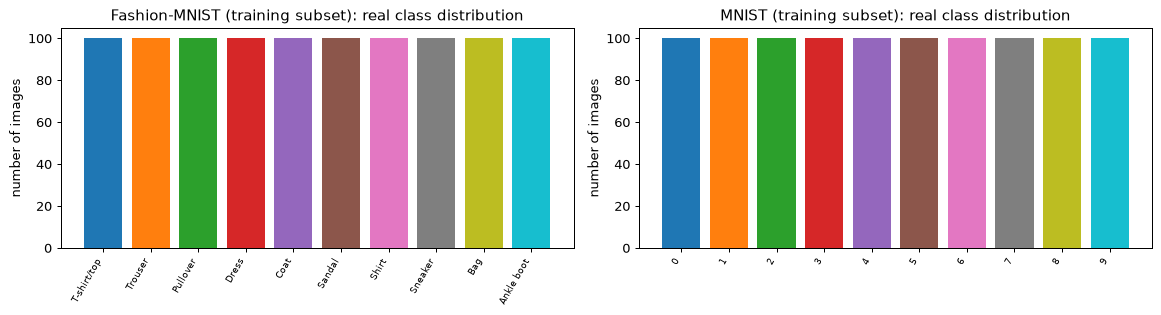

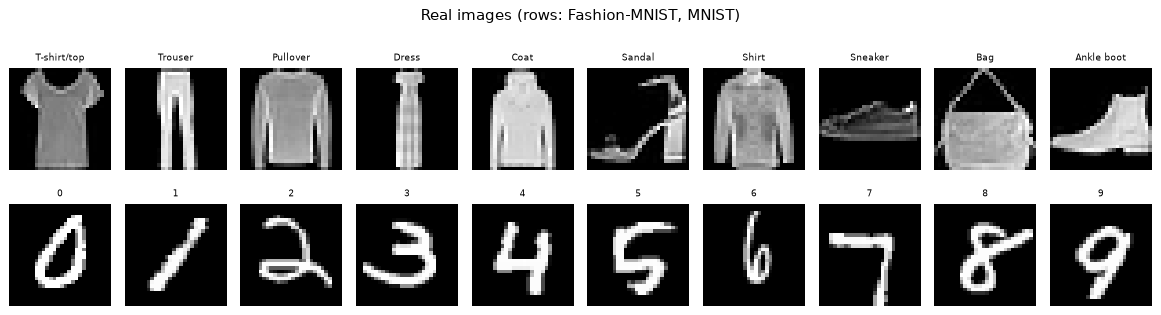

In [5]:
def describe(name, X, y, names, shape_img):
    print(f"=== {name} ===")
    print("  array shape:", tuple(X.shape), f"-> images of {shape_img[0]} x {shape_img[1]}, {X.shape[1]} features")
    fn = [f"pixel_{i}" for i in range(X.shape[1])]
    print("  feature names:", fn[:3], "...", fn[-2:], "(grey value in [0, 1])")
    print("  original label values:", sorted(set(y.tolist())), "->", [names[k] for k in sorted(set(y.tolist()))])
    print("  class counts:", dict(zip(sorted(set(y.tolist())), np.bincount(y.numpy()).tolist())))

for ds in DATASETS:
    describe(SPECS[ds]["title"] + " (training subset)", DATA[ds]["Xtr"], DATA[ds]["ytr"], SPECS[ds]["names"], (IMG, IMG))

fig, axs = plt.subplots(1, len(DATASETS), figsize=(6.5 * len(DATASETS), 3.6))
for ax, ds in zip(np.atleast_1d(axs), DATASETS):
    cnt = np.bincount(DATA[ds]["ytr"].numpy()); ax.bar(range(len(cnt)), cnt, color=[plt.cm.tab10(k % 10) for k in range(len(cnt))])
    ax.set_xticks(range(len(cnt))); ax.set_xticklabels(SPECS[ds]["names"], rotation=60, ha="right", fontsize=7)
    ax.set_title(SPECS[ds]["title"] + " (training subset): real class distribution"); ax.set_ylabel("number of images")
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(len(DATASETS), 10, figsize=(13, 1.5 * len(DATASETS) + 0.8))
for r, ds in enumerate(DATASETS):
    for k in range(10):
        i = int((DATA[ds]["ytr"] == k).nonzero()[0, 0]); axs[r, k].imshow(DATA[ds]["Xtr"][i].reshape(IMG, IMG), cmap="gray"); axs[r, k].axis("off")
        axs[r, k].set_title(SPECS[ds]["names"][k], fontsize=7)
plt.suptitle("Real images (rows: " + ", ".join(SPECS[d]["title"] for d in DATASETS) + ")"); plt.tight_layout(); plt.show()

Fashion-MNIST: explained variance of the two coordinates: pixels 0.46, amplitudes 0.37


MNIST: explained variance of the two coordinates: pixels 0.17, amplitudes 0.17


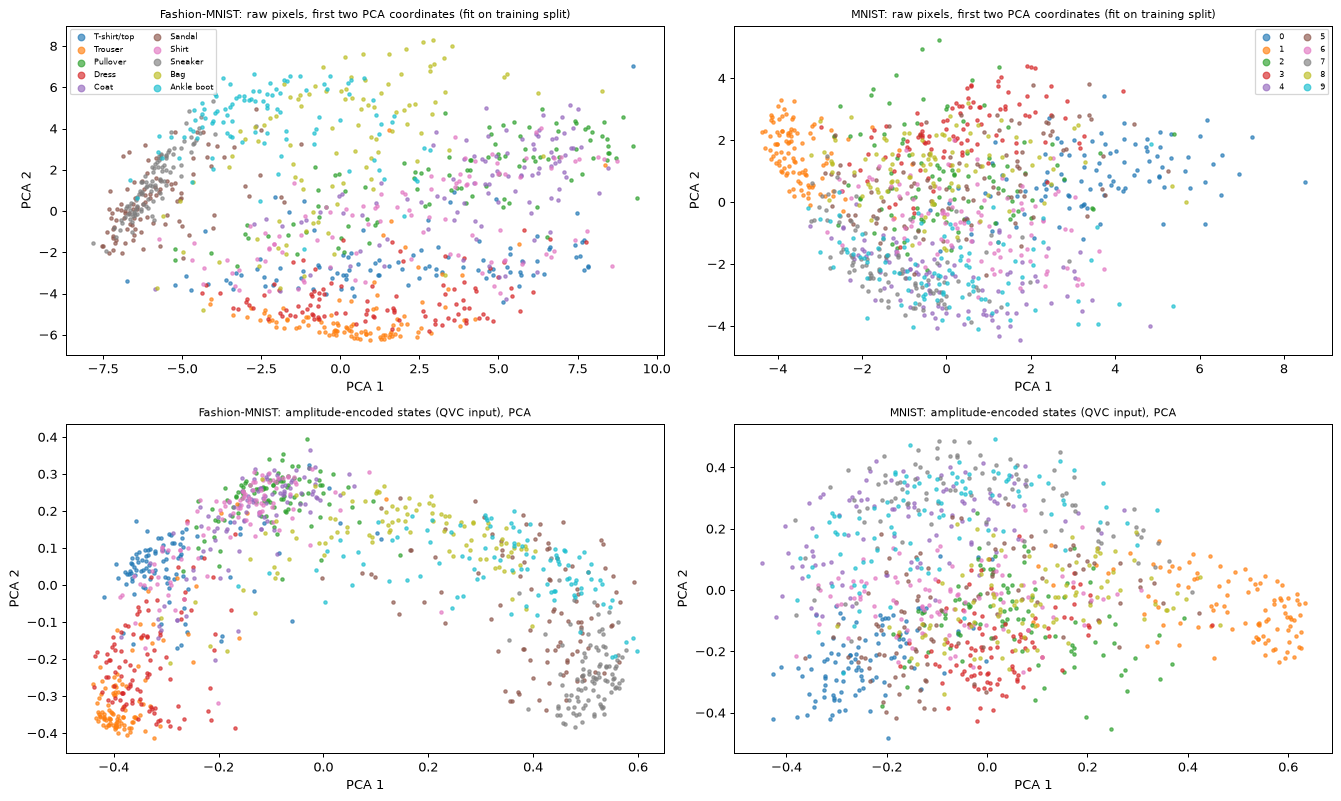

In [6]:
# Scatter of the real observations in the first two PCA coordinates (PCA fitted on the training split), coloured by ground-truth label.
def pca_scatter(ax, Ztr, ytr, names, title):
    for k in np.unique(ytr):
        m = ytr == k; ax.scatter(Ztr[m, 0], Ztr[m, 1], s=7, alpha=0.65, color=plt.cm.tab10(int(k) % 10), label=names[int(k)])
    ax.set_title(title, fontsize=9); ax.set_xlabel("PCA 1"); ax.set_ylabel("PCA 2")

def amp_np(X, nq=NQ):
    """normalised, zero-padded amplitude vectors as numpy (same map as amp_encode below)"""
    B, P = X.shape; buf = np.zeros((B, 2 ** nq), np.float32); buf[:, :P] = X
    return buf / np.maximum(np.linalg.norm(buf, axis=1, keepdims=True), 1e-12)

fig, axs = plt.subplots(2, len(DATASETS), figsize=(7.5 * len(DATASETS), 9))
for c, ds in enumerate(DATASETS):
    ytr = DATA[ds]["ytr"].numpy(); Xtr = DATA[ds]["Xtr"].numpy()
    p = PCA(n_components=2, random_state=SEED).fit(Xtr)
    pca_scatter(axs[0, c], p.transform(Xtr), ytr, SPECS[ds]["names"], f"{SPECS[ds]['title']}: raw pixels, first two PCA coordinates (fit on training split)")
    axs[0, c].legend(fontsize=6, ncol=2, markerscale=2)
    A = amp_np(Xtr); pa = PCA(n_components=2, random_state=SEED).fit(A)
    pca_scatter(axs[1, c], pa.transform(A), ytr, SPECS[ds]["names"], f"{SPECS[ds]['title']}: amplitude-encoded states (QVC input), PCA")
    print(f"{SPECS[ds]['title']}: explained variance of the two coordinates: pixels {p.explained_variance_ratio_.sum():.2f}, amplitudes {pa.explained_variance_ratio_.sum():.2f}")
plt.tight_layout(); plt.show()

## 2. Amplitude encoding and the quantum variational classifier (QVC)

**Encoding (Eq. 3).** `psi(x) = x / ||x||` zero-padded from 784 to 1 024 real amplitudes: the 10 qubits hold the whole image. The map is differentiable, so gradients with respect to the *pixels* exist.

**Classifier.** `U(theta) = prod_l [ CZ-chain . (Rot on every qubit) ]`: layer `l` applies `Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)` to each of the 10 qubits, then `CZ(0,1) CZ(1,2) ... CZ(8,9)`.
The class scores are the expectation values `<Z_k>`, `k = 0..9`, of the first ten qubits (here all of them) and the prediction is their argmax (Eq. 4); the logits for the cross-entropy are `LOGIT_SCALE * <Z_k>`.

**Simulator.** The QVC is simulated exactly with a batched PyTorch state-vector code (PennyLane convention: qubit 0 is the most significant bit of the basis-state index). The 10 rotations of a layer are fused into two
32 x 32 matrices (qubits 0-4 and 5-9), and the CZ chain is a fixed vector of signs. Section 4 checks this simulator against the real PennyLane QNode and an independent Qiskit circuit.

In [7]:
def amp_encode(X, nq=NQ):
    """Eq. (3): |psi(x)> = sum_i x_i |i> / ||x||, zero padded to 2^nq amplitudes. X: [B, P] real -> [B, 2^nq] real. Differentiable."""
    B, P = X.shape
    buf = X.new_zeros(B, 2 ** nq); buf[:, :P] = X
    return buf / buf.pow(2).sum(1, keepdim=True).sqrt().clamp_min(1e-12)

def rot_mats(a):
    """Matrices of qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) for angles a[..., 3] -> [..., 2, 2]."""
    phi, th, om = a[..., 0], a[..., 1], a[..., 2]
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    e = lambda z: torch.polar(torch.ones_like(z), z)
    m00 = e(-(phi + om) / 2) * c; m01 = -e((phi - om) / 2) * s
    m10 = e(-(phi - om) / 2) * s; m11 = e((phi + om) / 2) * c
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)

def kron_group(Ug):
    """Ug [..., g, 2, 2] -> Kronecker product over the g qubits [..., 2^g, 2^g] (first qubit = most significant)."""
    M = Ug[..., 0, :, :]
    for j in range(1, Ug.shape[-3]):
        M = torch.einsum('...ij,...kl->...ikjl', M, Ug[..., j, :, :]).reshape(*M.shape[:-2], M.shape[-2] * 2, M.shape[-1] * 2)
    return M

def cz_signs(nq):
    """Diagonal of CZ(0,1) CZ(1,2) ... CZ(nq-2,nq-1): (-1)^(sum_i b_i b_{i+1}) over the basis states (qubit 0 = most significant bit)."""
    k = torch.arange(2 ** nq); s = torch.zeros(2 ** nq, dtype=torch.long)
    for i in range(nq - 1):
        s += ((k >> (nq - 1 - i)) & 1) * ((k >> (nq - 2 - i)) & 1)
    return (1 - 2 * (s % 2)).float()

def zsigns(nq, ncls):
    """Rows = eigenvalues (+1/-1) of Z_0 ... Z_{ncls-1} over the basis states."""
    return torch.stack([1 - 2 * ((torch.arange(2 ** nq) >> (nq - 1 - q)) & 1).float() for q in range(ncls)], 0)

class QVC(nn.Module):
    """L x [Rot on every qubit, CZ chain]; outputs LOGIT_SCALE * <Z_k>. Input: batch of real amplitude vectors [B, 2^nq]."""
    def __init__(self, nq, L, ncls, seed, init_std=INIT_STD, scale=LOGIT_SCALE):
        super().__init__()
        assert nq % 2 == 0
        g = torch.Generator().manual_seed(seed)
        self.nq, self.L, self.scale = nq, L, scale
        self.theta = nn.Parameter(init_std * torch.randn(L, nq, 3, generator=g))
        self.register_buffer("cz", cz_signs(nq)); self.register_buffer("zs", zsigns(nq, ncls))
    def expvals(self, psi):
        B, h = psi.shape[0], self.nq // 2
        U = rot_mats(self.theta); Ma = kron_group(U[:, :h]); MbT = kron_group(U[:, h:]).transpose(-1, -2)
        s = psi.to(CDT).reshape(B, 2 ** h, 2 ** (self.nq - h)); cz = self.cz.reshape(2 ** h, 2 ** (self.nq - h))
        for l in range(self.L):
            s = torch.matmul(torch.matmul(Ma[l], s), MbT[l]) * cz
        return (s.reshape(B, -1).abs() ** 2) @ self.zs.T
    def forward(self, psi):
        return self.scale * self.expvals(psi)

class PixelQVC(nn.Module):
    """Pixels -> amplitude encoding -> QVC logits, so that every model (quantum or classical) is a function pixels -> logits."""
    def __init__(self, qvc):
        super().__init__(); self.q = qvc
    def forward(self, x):
        return self.q(amp_encode(x))

def n_params(m):
    return sum(p.numel() for p in m.parameters())

print("QVC-A:", NQ, "qubits,", L_A, "layers,", n_params(QVC(NQ, L_A, N_CLASSES, 0)), "trainable angles | QVC-B:", L_B, "layers,", n_params(QVC(NQ, L_B, N_CLASSES, 0)), "angles")

QVC-A: 10 qubits, 10 layers, 300 trainable angles | QVC-B: 20 layers, 600 angles


## 3. The classical networks, the controls and the training loops

* **ConvNet**: three 3x3 convolutions (`CONV_WIDTHS` maps, ReLU, 2x2 max-pooling), then two fully connected layers.
* **ResNet-18**: four stages of two basic blocks, base width `RES_WIDTH`.
* **Controls (not in the paper)**: a softmax regression (LogReg) and a one-hidden-layer MLP. They are low-capacity classical models of about the same clean accuracy as the QVC and tell us whether
  "resists the ConvNet attack" is something special about the quantum circuit or a property of any weaker model.
* **Baselines on the QVC's own input**: an RBF-SVM and a random forest trained on the amplitude vectors (the 1 024 numbers the circuit receives).

All models are trained on the same `N_TRAIN` images. Every model is a function *pixels -> logits*, which makes the attacks model-agnostic.

In [8]:
class ConvNet(nn.Module):
    def __init__(self, ncls=10, w=CONV_WIDTHS):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(1, w[0], 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(w[0], w[1], 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                               nn.Conv2d(w[1], w[2], 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(w[2] * 9, 64), nn.ReLU(), nn.Linear(64, ncls))
    def forward(self, x): return self.f(x.reshape(-1, 1, IMG, IMG))

class Block(nn.Module):
    def __init__(self, i, o, stride):
        super().__init__()
        self.c1 = nn.Conv2d(i, o, 3, stride, 1, bias=False); self.b1 = nn.BatchNorm2d(o); self.c2 = nn.Conv2d(o, o, 3, 1, 1, bias=False); self.b2 = nn.BatchNorm2d(o)
        self.sh = None if (stride == 1 and i == o) else nn.Sequential(nn.Conv2d(i, o, 1, stride, bias=False), nn.BatchNorm2d(o))
    def forward(self, x):
        y = self.b2(self.c2(F.relu(self.b1(self.c1(x)))))
        return F.relu(y + (x if self.sh is None else self.sh(x)))

class ResNet18(nn.Module):
    """ResNet-18 layout (4 stages x 2 basic blocks) with base width w (CHOICE: 16 instead of 64) for 1-channel images."""
    def __init__(self, ncls=10, w=RES_WIDTH):
        super().__init__()
        cfg = [(w, w, 1), (w, w, 1), (w, 2 * w, 2), (2 * w, 2 * w, 1), (2 * w, 4 * w, 2), (4 * w, 4 * w, 1), (4 * w, 8 * w, 2), (8 * w, 8 * w, 1)]
        self.stem = nn.Sequential(nn.Conv2d(1, w, 3, 1, 1, bias=False), nn.BatchNorm2d(w), nn.ReLU())
        self.blocks = nn.Sequential(*[Block(*c) for c in cfg]); self.fc = nn.Linear(8 * w, ncls)
    def forward(self, x):
        h = self.blocks(self.stem(x.reshape(-1, 1, IMG, IMG)))
        return self.fc(F.adaptive_avg_pool2d(h, 1).flatten(1))

def LogReg(ncls=10): return nn.Linear(IMG * IMG, ncls)
def MLP(ncls=10, h=64): return nn.Sequential(nn.Linear(IMG * IMG, h), nn.ReLU(), nn.Linear(h, ncls))

def train_net(model, X, y, epochs, seed, bs=64, lr=CNN_LR):
    """Adam + cross-entropy on pixels (classical networks and controls)."""
    torch.manual_seed(seed); opt = torch.optim.Adam(model.parameters(), lr=lr); g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]; loss = F.cross_entropy(model(X[idx]), y[idx]); opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

@torch.no_grad()
def predict_logits(fn, X, bs=250):
    return torch.cat([fn(X[i:i + bs]) for i in range(0, len(X), bs)])

def acc_fn(fn, X, y):
    return float((predict_logits(fn, X).argmax(1) == y).float().mean())

def train_qvc(psi_tr, y_tr, X_va, y_va, seed, L, epochs, bs, lr):
    """Adam + cross-entropy + one-cycle learning rate (CHOICE). Returns the model and the validation accuracy after every epoch."""
    torch.manual_seed(seed)
    model = QVC(NQ, L, N_CLASSES, seed); opt = torch.optim.Adam(model.parameters(), lr=lr)
    nst = epochs * ((len(psi_tr) + bs - 1) // bs); sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=nst, pct_start=0.1)
    g = torch.Generator().manual_seed(seed); hist = []; pva = amp_encode(X_va)
    for ep in range(epochs):
        perm = torch.randperm(psi_tr.shape[0], generator=g)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(model(psi_tr[idx]), y_tr[idx]); opt.zero_grad(); loss.backward(); opt.step(); sch.step()
        with torch.no_grad():
            hist.append(float((model(pva).argmax(1) == y_va).float().mean()))
    return model.eval(), hist

Fashion-MNIST  [675 s] clean TEST accuracy: QVC-A 67.3, QVC-B 71.7, ConvNet 73.7, ResNet-18 74.7, LogReg 78.0, MLP-64 74.3, SVC(amplitudes) 81.0, RF(amplitudes) 79.7


MNIST          [1501 s] clean TEST accuracy: QVC-A 67.0, QVC-B 73.7, ConvNet 91.3, ResNet-18 92.7, LogReg 84.0, MLP-64 88.7, SVC(amplitudes) 92.3, RF(amplitudes) 88.3


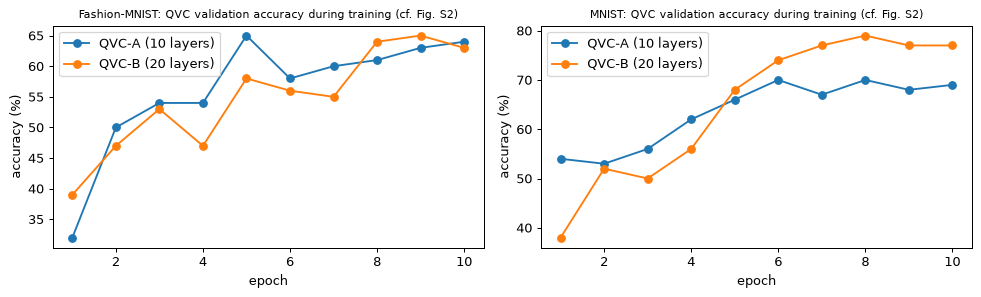

In [9]:
MODELS = {ds: {} for ds in DATASETS}; HIST = {}; FN = {ds: {} for ds in DATASETS}; TRAIN_TIME = {}
BASE = {ds: {} for ds in DATASETS}
t0 = time.time()
for ds in DATASETS:
    d = DATA[ds]; M = MODELS[ds]; ptr = amp_encode(d["Xtr"])
    for name, L in (("QVC-A", L_A), ("QVC-B", L_B)):
        t1 = time.time(); m, h = train_qvc(ptr, d["ytr"], d["Xva"], d["yva"], SEED, L, EPOCHS, BATCH, LR_QVC)
        M[name] = m; HIST[(ds, name)] = h; TRAIN_TIME[(ds, name)] = time.time() - t1; FN[ds][name] = PixelQVC(m).eval()
    for name, mk, ep in (("ConvNet", ConvNet, CNN_EPOCHS), ("ResNet-18", ResNet18, CNN_EPOCHS), ("LogReg", LogReg, 30), ("MLP-64", MLP, 30)):
        t1 = time.time(); torch.manual_seed(SEED)
        M[name] = train_net(mk(), d["Xtr"], d["ytr"], ep, SEED, lr=(CNN_LR if name in ("ConvNet", "ResNet-18") else 5e-3)); FN[ds][name] = M[name]; TRAIN_TIME[(ds, name)] = time.time() - t1
    Atr, Ate = amp_encode(d["Xtr"]).numpy(), amp_encode(d["Xte"]).numpy()
    svc = SVC(kernel="rbf", C=10, gamma="scale").fit(Atr, d["ytr"].numpy())                                # CHOICE: C = 10
    rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1).fit(Atr, d["ytr"].numpy())
    BASE[ds] = dict(svc=svc, rf=rf)
    print(f"{SPECS[ds]['title']:14s} [{time.time() - t0:.0f} s] clean TEST accuracy: " + ", ".join(f"{k} {100 * acc_fn(FN[ds][k], d['Xte'], d['yte']):.1f}" for k in ("QVC-A", "QVC-B", "ConvNet", "ResNet-18", "LogReg", "MLP-64"))
          + f", SVC(amplitudes) {100 * svc.score(Ate, d['yte'].numpy()):.1f}, RF(amplitudes) {100 * rf.score(Ate, d['yte'].numpy()):.1f}")

fig, axs = plt.subplots(1, len(DATASETS), figsize=(5.5 * len(DATASETS), 3.4))
for ax, ds in zip(np.atleast_1d(axs), DATASETS):
    for name, col in (("QVC-A", "tab:blue"), ("QVC-B", "tab:orange")):
        ax.plot(range(1, EPOCHS + 1), 100 * np.array(HIST[(ds, name)]), "o-", color=col, label=f"{name} ({L_A if name == 'QVC-A' else L_B} layers)")
    ax.set_title(f"{SPECS[ds]['title']}: QVC validation accuracy during training (cf. Fig. S2)", fontsize=9); ax.set_xlabel("epoch"); ax.set_ylabel("accuracy (%)"); ax.legend()
plt.tight_layout(); plt.show()

In [10]:
rows = []
for ds in DATASETS:
    d = DATA[ds]; Ate = amp_encode(d["Xte"]).numpy(); r = dict(dataset=SPECS[ds]["title"])
    for k in ("QVC-A", "QVC-B", "ConvNet", "ResNet-18", "LogReg", "MLP-64"):
        r[k] = round(100 * acc_fn(FN[ds][k], d["Xte"], d["yte"]), 1)
    r["SVC(rbf, amplitudes)"] = round(100 * BASE[ds]["svc"].score(Ate, d["yte"].numpy()), 1); r["RF(amplitudes)"] = round(100 * BASE[ds]["rf"].score(Ate, d["yte"].numpy()), 1)
    rows.append(r)
CLEAN = pd.DataFrame(rows); print(f"Clean test accuracy (%) on {N_TEST} test images, models trained on {N_TRAIN} images (paper: full training set, accuracies shown only in figures S2, S3):")
display(CLEAN)
print("parameters:", {k: n_params(v) for k, v in MODELS[DATASETS[0]].items()})
print("training time (s):", {f"{k[0]}/{k[1]}": round(v) for k, v in TRAIN_TIME.items()})

Clean test accuracy (%) on 300 test images, models trained on 1000 images (paper: full training set, accuracies shown only in figures S2, S3):


,dataset,QVC-A,QVC-B,ConvNet,ResNet-18,LogReg,MLP-64,"SVC(rbf, amplitudes)",RF(amplitudes)
0,Fashion-MNIST,67.3,71.7,73.7,74.7,78.0,74.3,81.0,79.7
1,MNIST,67.0,73.7,91.3,92.7,84.0,88.7,92.3,88.3


parameters: {'QVC-A': 300, 'QVC-B': 600, 'ConvNet': 60874, 'ResNet-18': 701178, 'LogReg': 7850, 'MLP-64': 50890}
training time (s): {'fmnist/QVC-A': 56, 'fmnist/QVC-B': 75, 'fmnist/ConvNet': 58, 'fmnist/ResNet-18': 473, 'fmnist/LogReg': 2, 'fmnist/MLP-64': 4, 'mnist/QVC-A': 39, 'mnist/QVC-B': 95, 'mnist/ConvNet': 51, 'mnist/ResNet-18': 619, 'mnist/LogReg': 3, 'mnist/MLP-64': 7}


## Quantum Circuit Architecture

Everything below is **the object that is executed**: the QVC as a PennyLane QNode (`StatePrep`, `Rot`, `CZ`, Pauli-Z read-out), drawn from the real QNode with the trained angles, and an independent Qiskit circuit
(Shende-Bullock-Markov state preparation of the image followed by the same layers). The PyTorch simulator that produced all numbers in this notebook is asserted to agree with both.

* encoding: amplitude encoding, `StatePrep` of the 1 024 real amplitudes (the paper estimates "a few thousand gates" for loading; the Qiskit exact preparation is counted below);
* trainable part: `L` layers of `Rot` on each of the 10 qubits followed by 9 nearest-neighbour CZ gates (39 gates per layer, as stated in the paper's Sec. II D);
* measurement: `<Z_k>` of all ten qubits (the first `m` = 10 qubits), prediction = argmax.

Assumptions where the paper omits details: the exact rotation gates (we use `Rot` with the same three parameters per qubit and layer), the order inside a layer (rotations first, then the CZ chain, as in the text),
the open (non-periodic) CZ chain (9 CZ gates per layer = 39 gates per layer), the number of layers (see configuration) and the initial angles.

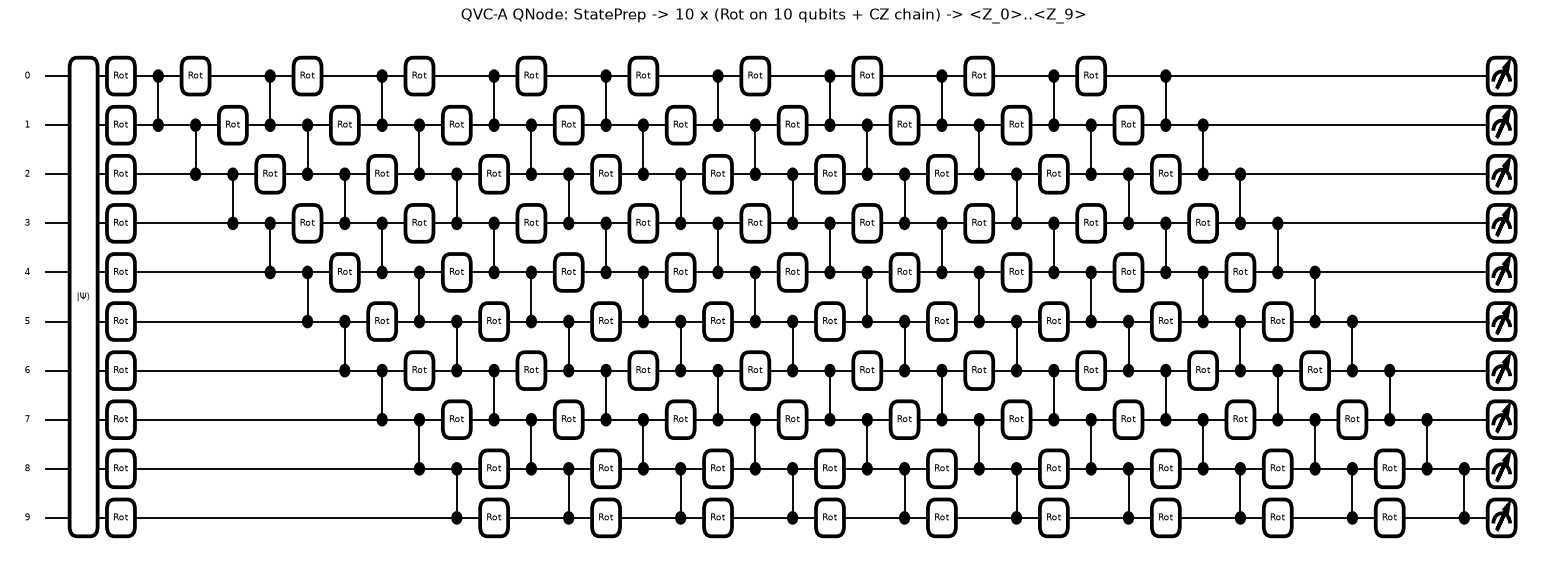

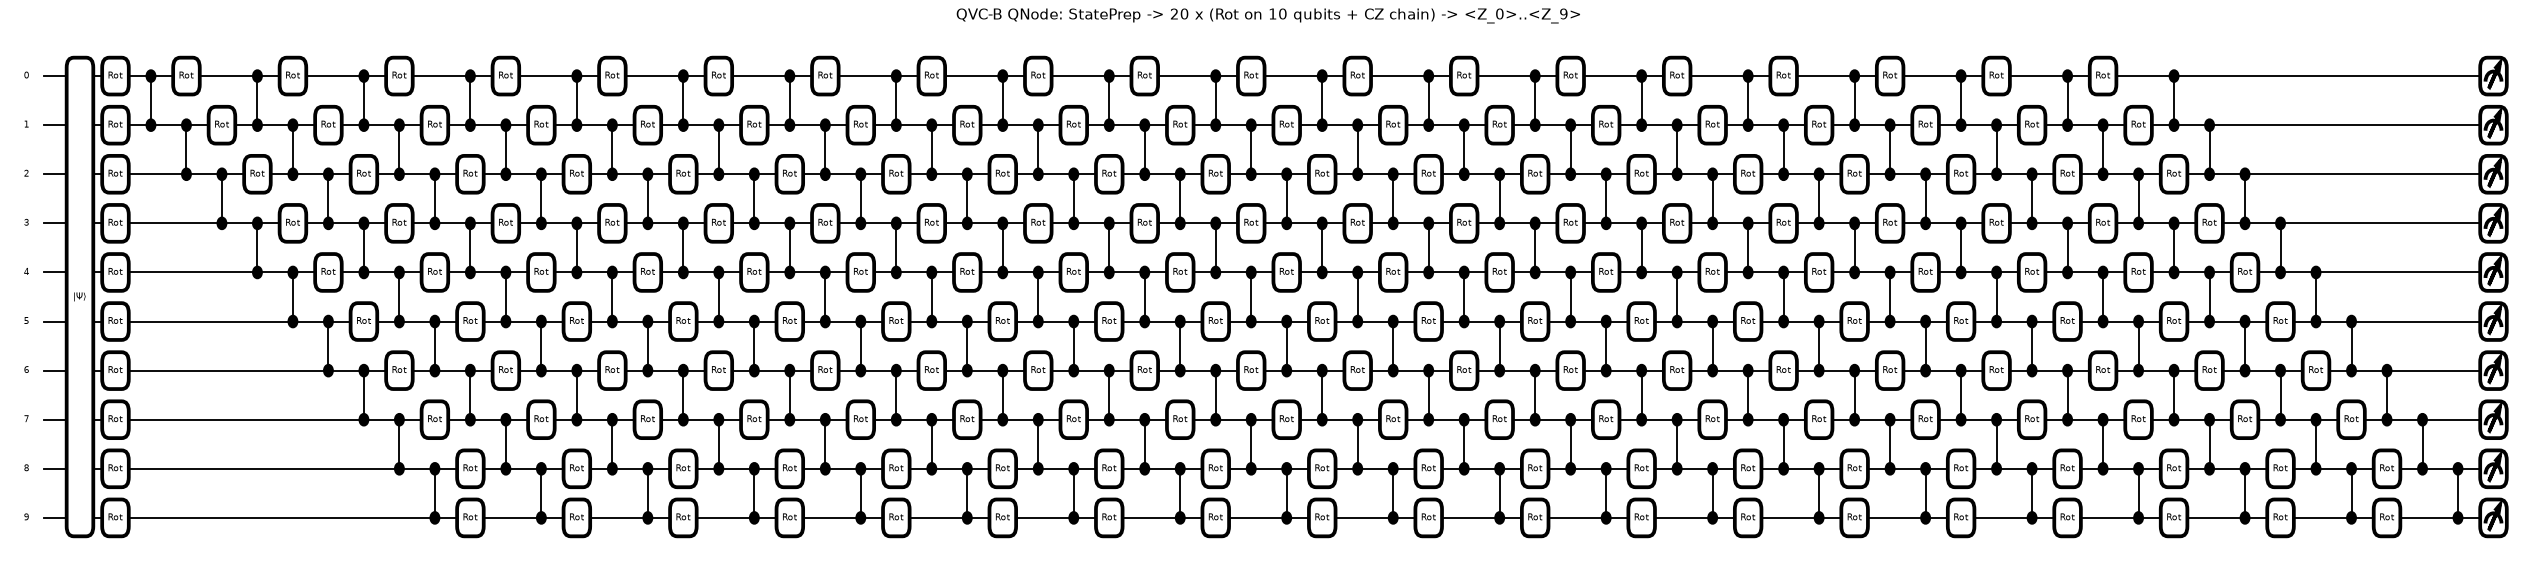

In [11]:
ds0 = DATASETS[0]; x_in = amp_encode(DATA[ds0]["Xte"][:3])
dev = qml.device("default.qubit", wires=NQ)
Zs = [qml.Z(j) for j in range(N_CLASSES)]

@qml.qnode(dev, interface="torch", diff_method="backprop")
def qvc_qnode(psi, theta):
    qml.StatePrep(psi, wires=range(NQ), normalize=True)                       # amplitude encoding of the image
    for l in range(theta.shape[0]):
        for q in range(NQ):
            qml.Rot(theta[l, q, 0], theta[l, q, 1], theta[l, q, 2], wires=q)   # three trainable angles per qubit and layer
        for q in range(NQ - 1):
            qml.CZ(wires=[q, q + 1])                                           # nearest-neighbour entangling chain
    return [qml.expval(z) for z in Zs]

for name in ("QVC-A", "QVC-B"):
    th = MODELS[ds0][name].theta.detach().double()
    fig, ax = qml.draw_mpl(qvc_qnode, decimals=None, fontsize=7)(x_in[0].to(torch.complex128), th)
    fig.set_size_inches(min(48, 1.1 * th.shape[0] + 6), 6); plt.title(f"{name} QNode: StatePrep -> {th.shape[0]} x (Rot on 10 qubits + CZ chain) -> <Z_0>..<Z_9>"); plt.show()

In [12]:
# Equivalence: PyTorch simulator == PennyLane QNode == Qiskit circuit, for both architectures and three images.
def to_qiskit_vec(psi, nq):
    """PennyLane ordering (qubit 0 = most significant) -> Qiskit ordering (qubit 0 = least significant)."""
    a = np.asarray(psi, dtype=np.complex128).reshape((2,) * nq)
    v = np.transpose(a, tuple(range(nq))[::-1]).reshape(-1)
    return v / np.linalg.norm(v)

def qvc_circuit(theta, nq):
    qc = QuantumCircuit(nq, name="QVC")
    for l in range(theta.shape[0]):
        for q in range(nq):
            qc.rz(float(theta[l, q, 0]), q); qc.ry(float(theta[l, q, 1]), q); qc.rz(float(theta[l, q, 2]), q)   # Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)
        for q in range(nq - 1):
            qc.cz(q, q + 1)
    return qc

def zexp_from_probs(p, nq, ncls):
    k = np.arange(2 ** nq); s = [1 - 2 * ((k >> q) & 1) for q in range(nq)]          # Qiskit: qubit q = bit q of the index
    return np.array(s[:ncls]) @ p

EQUIV = []
for name in ("QVC-A", "QVC-B"):
    mq = MODELS[ds0][name]; th = mq.theta.detach().double()
    ours = mq.expvals(x_in).detach().double()
    ref = torch.stack([torch.stack(qvc_qnode(x_in[i].to(torch.complex128), th)) for i in range(3)])
    e_pl = float((ours - ref).abs().max())
    qk = mq.theta.detach().numpy(); qc_q = qvc_circuit(qk, NQ)
    e_qk = 0.0
    for i in range(2):
        full = QuantumCircuit(NQ); full.append(StatePreparation(to_qiskit_vec(x_in[i].numpy(), NQ)), range(NQ)); full = full.compose(qc_q)
        z_q = zexp_from_probs(Statevector(full).probabilities(), NQ, N_CLASSES)
        e_qk = max(e_qk, float(np.abs(z_q - ours[i].numpy()).max()))
    assert e_pl < 1e-4, (name, "PennyLane disagrees", e_pl); assert e_qk < 1e-3, (name, "Qiskit disagrees", e_qk)
    assert qc_q.size() == th.shape[0] * (3 * NQ + (NQ - 1)), "gate count per layer must be 39 as in the paper"
    EQUIV.append(dict(model=name, qubits=NQ, layers=int(th.shape[0]), trainable_angles=int(th.numel()), gates_per_layer=qc_q.size() // th.shape[0], total_gates=qc_q.size(),
                      depth_as_drawn=qc_q.depth(), max_err_vs_PennyLane=e_pl, max_err_vs_Qiskit=e_qk))
t0 = time.time(); tq = transpile(QuantumCircuit(NQ).compose(QuantumCircuit(NQ)), basis_gates=["cx", "u"])
load = QuantumCircuit(NQ); load.append(StatePreparation(to_qiskit_vec(x_in[0].numpy(), NQ)), range(NQ))
tl = transpile(load, basis_gates=["cx", "u"], optimization_level=1, seed_transpiler=SEED); ops = tl.count_ops()
print(f"exact Shende-Bullock-Markov loading of one image: {ops.get('cx', 0)} CNOT, depth {tl.depth()}, {tl.size()} gates after transpiling to {{cx, u}} ({time.time() - t0:.1f} s)  [paper: 'a few thousand gates']")
display(pd.DataFrame(EQUIV))
print("PyTorch simulator == PennyLane QNode == Qiskit circuit (asserted above).")

exact Shende-Bullock-Markov loading of one image: 1013 CNOT, depth 2027, 2036 gates after transpiling to {cx, u} (18.1 s)  [paper: 'a few thousand gates']


,model,qubits,layers,trainable_angles,gates_per_layer,total_gates,depth_as_drawn,max_err_vs_PennyLane,max_err_vs_Qiskit
0,QVC-A,10,10,300,39,390,57,3.304637e-07,3.456694e-07
1,QVC-B,10,20,600,39,780,107,1.841294e-07,1.885833e-07


PyTorch simulator == PennyLane QNode == Qiskit circuit (asserted above).


## 4. Transfer and defence (claims C1-C5, Fig. 2 and Figs. S5)

White-box attacks are crafted on each of four source networks (ConvNet, ResNet-18, QVC-A, QVC-B) for `N_ATK` test images and every strength `eps`, then fed to **every** target (including the source).
Following Fig. S4 of the paper, *transferability* is an attack crafted on one network applied to another network of the same kind (ConvNet to ResNet, QVC-A to QVC-B) and *defence* is an attack from the other kind
(ConvNet to QVC, QVC to ConvNet). PGD uses a random start, `PGD_STEPS` signed-gradient steps of size `2.5 eps / steps`, projection to the l-inf ball and clipping to [0, 1]. FGSM is a single step of size `eps`.
We also report the SVC / random forest (trained on amplitude vectors) as non-differentiable targets and the two low-capacity controls.

Accuracy is measured on **all** attacked test images (the paper's convention). Because the QVC starts from a lower clean accuracy than the ConvNet, the table also gives the *retention* (accuracy under attack divided by clean accuracy on the same images).

In [13]:
def craft(fn, X, y, eps, steps, seed, kind="pgd", loss="ce", restarts=1, bs=50, target=None):
    """l-inf attack on `fn` (pixels -> logits). kind: 'pgd' (random start, `steps` steps of 2.5 eps/steps) or 'fgsm'. loss: 'ce' or 'margin' (best other logit minus true logit).
    With restarts > 1 the first restart that fools the model is kept per image. With `target` (labels) the attack is targeted: it descends the cross-entropy towards `target`."""
    if eps == 0:
        return X.clone()
    g = torch.Generator().manual_seed(seed); out = []; sgn = 1.0 if target is None else -1.0
    def lossf(z, t):
        if loss == "ce":
            return F.cross_entropy(z, t, reduction="sum")
        oh = F.one_hot(t, z.shape[1]).bool()
        return (z.masked_fill(oh, -1e9).max(1).values - z[oh]).sum()
    for s in range(0, len(X), bs):
        x, t = X[s:s + bs], y[s:s + bs]; lab = t if target is None else target[s:s + bs]; best = None; fooled = None
        for r in range(restarts):
            if kind == "fgsm":
                xa = x.clone().requires_grad_(True)
                gr, = torch.autograd.grad(lossf(fn(xa), lab), xa); cand = (x + sgn * eps * gr.sign()).clamp(0, 1).detach()
            else:
                alpha = 2.5 * eps / steps
                xa = (x + (2 * torch.rand(x.shape, generator=g) - 1) * eps).clamp(0, 1)
                for _ in range(steps):
                    xa = xa.detach().requires_grad_(True)
                    gr, = torch.autograd.grad(lossf(fn(xa), lab), xa)
                    xa = (x + (xa.detach() + sgn * alpha * gr.sign() - x).clamp(-eps, eps)).clamp(0, 1)
                cand = xa.detach()
            with torch.no_grad():
                pr = fn(cand).argmax(1); wrong = (pr != t) if target is None else (pr == lab)
            if best is None:
                best, fooled = cand.clone(), wrong.clone()
            else:
                take = wrong & ~fooled; best[take] = cand[take]; fooled |= wrong
        out.append(best)
    return torch.cat(out)

SRCS = ["ConvNet", "ResNet-18", "QVC-A", "QVC-B"]
TGTS = ["ConvNet", "ResNet-18", "QVC-A", "QVC-B", "LogReg", "MLP-64", "SVC(amp)", "RF(amp)"]

def predict_labels(ds, name, X):
    if name == "SVC(amp)": return torch.as_tensor(BASE[ds]["svc"].predict(amp_encode(X).numpy()))
    if name == "RF(amp)":  return torch.as_tensor(BASE[ds]["rf"].predict(amp_encode(X).numpy()))
    return predict_logits(FN[ds][name], X).argmax(1)

ADVX = {}; t0 = time.time()
for ds in DATASETS:
    d = DATA[ds]; XT, YT = d["Xte"][:N_ATK], d["yte"][:N_ATK]
    for kind in ("pgd", "fgsm"):
        for src in SRCS:
            for eps in EPS_LIST:
                ADVX[(ds, kind, src, eps)] = craft(FN[ds][src], XT, YT, eps, PGD_STEPS, SEED, kind=kind)
    print(f"{SPECS[ds]['title']}: attacks crafted on {SRCS}  [{time.time() - t0:.0f} s]")

rows = []
for (ds, kind, src, eps), Xa in ADVX.items():
    YT = DATA[ds]["yte"][:N_ATK]
    for tgt in TGTS:
        p = predict_labels(ds, tgt, Xa); rows.append(dict(dataset=ds, attack=kind, source=src, target=tgt, eps=eps, acc=float((p == YT).float().mean())))
RES = pd.DataFrame(rows)
def A(ds, kind, src, tgt, eps):
    return float(RES[(RES.dataset == ds) & (RES.attack == kind) & (RES.source == src) & (RES.target == tgt) & (RES.eps == eps)].acc.iloc[0])
print("done; accuracy table has", len(RES), "rows")

Fashion-MNIST: attacks crafted on ['ConvNet', 'ResNet-18', 'QVC-A', 'QVC-B']  [131 s]


MNIST: attacks crafted on ['ConvNet', 'ResNet-18', 'QVC-A', 'QVC-B']  [286 s]


done; accuracy table has 512 rows


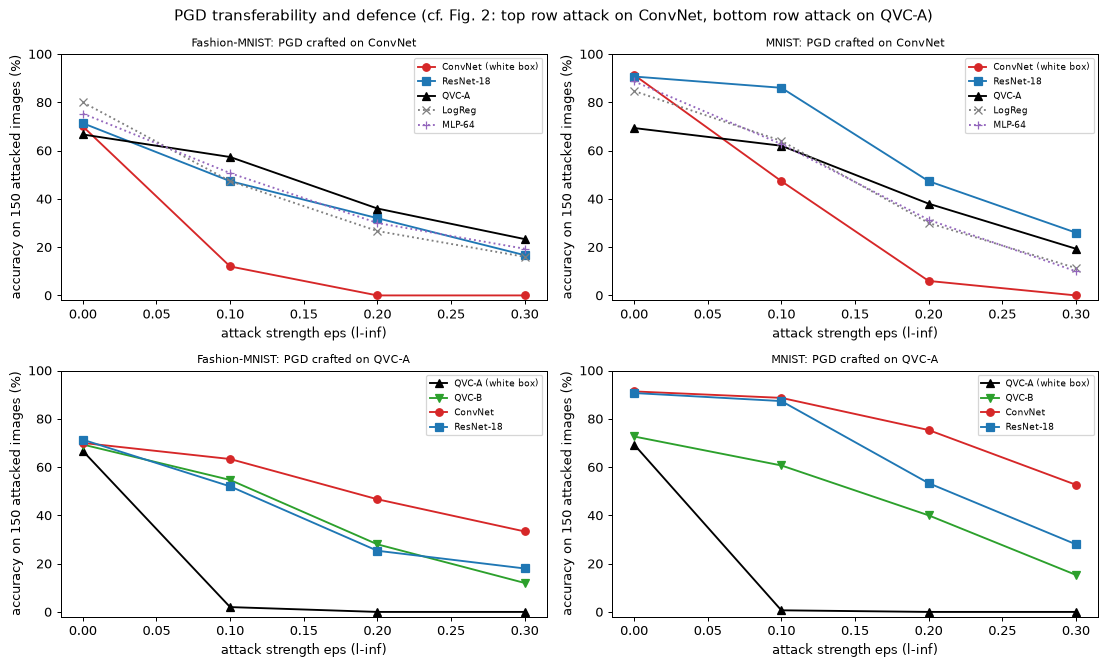

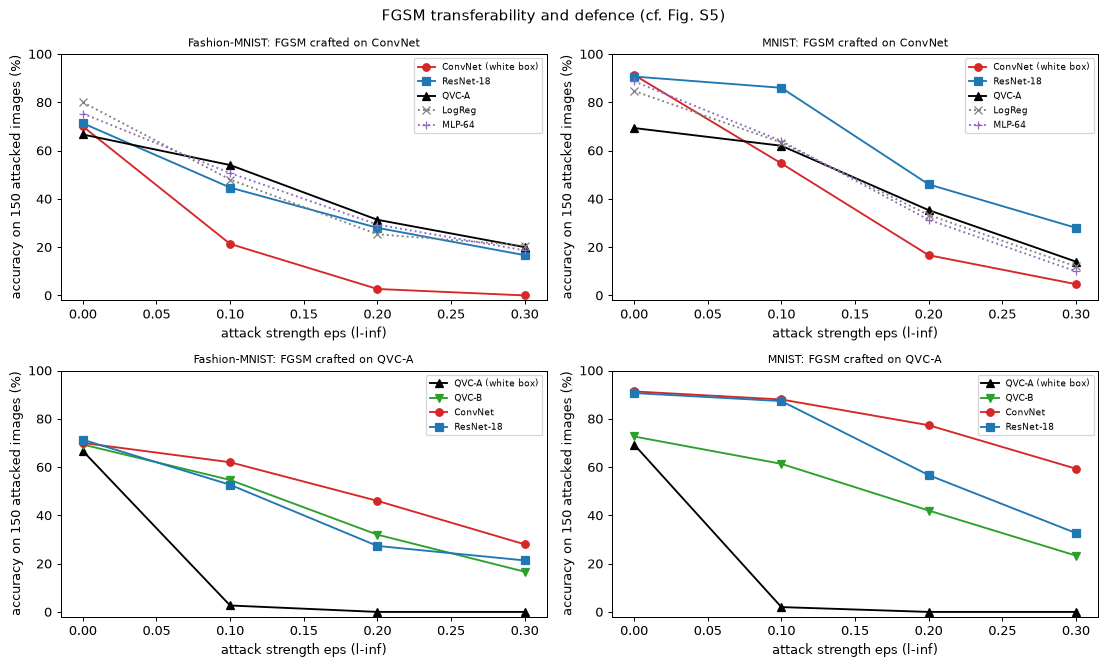

In [14]:
STY = {"ConvNet": ("tab:red", "o-"), "ResNet-18": ("tab:blue", "s-"), "QVC-A": ("k", "^-"), "QVC-B": ("tab:green", "v-"), "LogReg": ("tab:gray", "x:"), "MLP-64": ("tab:purple", "+:")}
def fig2(kind, title):
    fig, axs = plt.subplots(2, len(DATASETS), figsize=(6.2 * len(DATASETS), 7.5), squeeze=False)
    for c, ds in enumerate(DATASETS):
        for r, (src, tg) in enumerate([("ConvNet", ["ConvNet", "ResNet-18", "QVC-A", "LogReg", "MLP-64"]), ("QVC-A", ["QVC-A", "QVC-B", "ConvNet", "ResNet-18"])]):
            for t in tg:
                col, st = STY[t]; axs[r, c].plot(EPS_LIST, [100 * A(ds, kind, src, t, e) for e in EPS_LIST], st, color=col, label=t + (" (white box)" if t == src else ""))
            axs[r, c].set_title(f"{SPECS[ds]['title']}: {kind.upper()} crafted on {src}", fontsize=9); axs[r, c].set_xlabel("attack strength eps (l-inf)"); axs[r, c].set_ylabel(f"accuracy on {N_ATK} attacked images (%)")
            axs[r, c].set_ylim(-2, 100); axs[r, c].legend(fontsize=7)
    plt.suptitle(title); plt.tight_layout(); plt.show()
fig2("pgd", "PGD transferability and defence (cf. Fig. 2: top row attack on ConvNet, bottom row attack on QVC-A)")
fig2("fgsm", "FGSM transferability and defence (cf. Fig. S5)")

In [15]:
EP = [e for e in EPS_LIST if e > 0]
for kind in ("pgd", "fgsm"):
    for ds in DATASETS:
        rows = []
        for src in SRCS:
            for tgt in TGTS:
                a0 = A(ds, kind, src, tgt, 0.0)
                rows.append(dict(source=src, target=tgt, **{f"eps={e}": round(100 * A(ds, kind, src, tgt, e), 1) for e in EPS_LIST}, **{f"retention@{e}": round(A(ds, kind, src, tgt, e) / max(a0, 1e-9), 2) for e in EP[1:2]}))
        print(f"\n{SPECS[ds]['title']}, {kind.upper()}: accuracy (%) of each target (rows grouped by the network the attack was crafted on)")
        display(pd.DataFrame(rows).set_index(["source", "target"]))


Fashion-MNIST, PGD: accuracy (%) of each target (rows grouped by the network the attack was crafted on)


eps=0.0  eps=0.1  eps=0.2  eps=0.3  retention@0.2
source    target                                                      
ConvNet   ConvNet       70.0     12.0      0.0      0.0           0.00
          ResNet-18     71.3     47.3     32.0     16.7           0.45
          QVC-A         66.7     57.3     36.0     23.3           0.54
          QVC-B         69.3     50.0     30.0     13.3           0.43
          LogReg        80.0     47.3     26.7     16.0           0.33
          MLP-64        75.3     50.7     30.0     19.3           0.40
          SVC(amp)      80.7     60.0     35.3     22.0           0.44
          RF(amp)       80.7     38.7     20.7     10.0           0.26
ResNet-18 ConvNet       70.0     67.3     61.3     50.7           0.88
          ResNet-18     71.3      0.0      0.0      0.0           0.00
          QVC-A         66.7     61.3     51.3     37.3           0.77
          QVC-B         69.3     64.0     51.3     34.0           0.74
          LogReg        80.0     67.3     53.3     34.7           0.67
          MLP-64        75.3     64.0     49.3     31.3           0.65
          SVC(amp)      80.7     74.7     65.3     58.7           0.81
          RF(amp)       80.7     62.7     44.0     36.0           0.55
QVC-A     ConvNet       70.0     63.3     46.7     33.3           0.67
          ResNet-18     71.3     52.0     25.3     18.0           0.36
          QVC-A         66.7      2.0      0.0      0.0           0.00
          QVC-B         69.3     54.7     28.0     12.0           0.40
          LogReg        80.0     63.3     36.0     19.3           0.45
          MLP-64        75.3     62.0     38.7     17.3           0.51
          SVC(amp)      80.7     70.7     53.3     36.0           0.66
          RF(amp)       80.7     61.3     28.0     17.3           0.35
QVC-B     ConvNet       70.0     61.3     43.3     30.0           0.62
          ResNet-18     71.3     46.7     27.3     19.3           0.38
          QVC-A         66.7     54.0     28.0     15.3           0.42
          QVC-B         69.3      0.0      0.0      0.0           0.00
          LogReg        80.0     57.3     30.7     22.0           0.38
          MLP-64        75.3     56.7     30.0     20.0           0.40
          SVC(amp)      80.7     69.3     50.0     29.3           0.62
          RF(amp)       80.7     48.0     22.7     14.0           0.28


MNIST, PGD: accuracy (%) of each target (rows grouped by the network the attack was crafted on)


eps=0.0  eps=0.1  eps=0.2  eps=0.3  retention@0.2
source    target                                                      
ConvNet   ConvNet       91.3     47.3      6.0      0.0           0.07
          ResNet-18     90.7     86.0     47.3     26.0           0.52
          QVC-A         69.3     62.0     38.0     19.3           0.55
          QVC-B         72.7     61.3     38.7     28.0           0.53
          LogReg        84.7     64.0     30.0     11.3           0.35
          MLP-64        88.7     62.7     31.3     10.0           0.35
          SVC(amp)      92.0     77.3     40.0     13.3           0.43
          RF(amp)       88.0     33.3     13.3      7.3           0.15
ResNet-18 ConvNet       91.3     86.0     79.3     72.7           0.87
          ResNet-18     90.7     20.0      0.0      0.0           0.00
          QVC-A         69.3     64.7     49.3     35.3           0.71
          QVC-B         72.7     62.0     48.0     36.0           0.66
          LogReg        84.7     80.7     66.7     56.7           0.79
          MLP-64        88.7     82.7     66.7     54.0           0.75
          SVC(amp)      92.0     86.7     80.0     68.0           0.87
          RF(amp)       88.0     66.7     47.3     38.0           0.54
QVC-A     ConvNet       91.3     88.7     75.3     52.7           0.82
          ResNet-18     90.7     87.3     53.3     28.0           0.59
          QVC-A         69.3      0.7      0.0      0.0           0.00
          QVC-B         72.7     60.7     40.0     15.3           0.55
          LogReg        84.7     74.7     56.7     32.0           0.67
          MLP-64        88.7     78.7     57.3     32.0           0.65
          SVC(amp)      92.0     86.0     73.3     54.0           0.80
          RF(amp)       88.0     64.0     39.3     28.0           0.45
QVC-B     ConvNet       91.3     87.3     74.0     43.3           0.81
          ResNet-18     90.7     90.7     51.3     26.7           0.57
          QVC-A         69.3     61.3     34.7     13.3           0.50
          QVC-B         72.7      4.7      0.0      0.0           0.00
          LogReg        84.7     72.0     49.3     23.3           0.58
          MLP-64        88.7     78.0     49.3     24.0           0.56
          SVC(amp)      92.0     84.0     63.3     39.3           0.69
          RF(amp)       88.0     50.0     24.7     20.0           0.28


Fashion-MNIST, FGSM: accuracy (%) of each target (rows grouped by the network the attack was crafted on)


eps=0.0  eps=0.1  eps=0.2  eps=0.3  retention@0.2
source    target                                                      
ConvNet   ConvNet       70.0     21.3      2.7      0.0           0.04
          ResNet-18     71.3     44.7     28.0     16.7           0.39
          QVC-A         66.7     54.0     31.3     20.0           0.47
          QVC-B         69.3     52.0     27.3     12.7           0.39
          LogReg        80.0     48.0     25.3     20.7           0.32
          MLP-64        75.3     50.7     29.3     18.7           0.39
          SVC(amp)      80.7     60.7     38.7     20.0           0.48
          RF(amp)       80.7     45.3     24.7     13.3           0.31
ResNet-18 ConvNet       70.0     65.3     57.3     47.3           0.82
          ResNet-18     71.3      2.7      0.0      0.0           0.00
          QVC-A         66.7     58.7     46.0     29.3           0.69
          QVC-B         69.3     63.3     56.0     35.3           0.81
          LogReg        80.0     62.0     44.0     31.3           0.55
          MLP-64        75.3     62.0     40.0     28.0           0.53
          SVC(amp)      80.7     72.7     58.7     48.7           0.73
          RF(amp)       80.7     63.3     44.7     28.0           0.55
QVC-A     ConvNet       70.0     62.0     46.0     28.0           0.66
          ResNet-18     71.3     52.7     27.3     21.3           0.38
          QVC-A         66.7      2.7      0.0      0.0           0.00
          QVC-B         69.3     54.7     32.0     16.7           0.46
          LogReg        80.0     64.0     38.7     22.7           0.48
          MLP-64        75.3     62.0     40.0     20.7           0.53
          SVC(amp)      80.7     70.7     57.3     38.7           0.71
          RF(amp)       80.7     64.0     42.0     25.3           0.52
QVC-B     ConvNet       70.0     60.7     42.0     28.7           0.60
          ResNet-18     71.3     49.3     29.3     22.0           0.41
          QVC-A         66.7     52.7     30.0     21.3           0.45
          QVC-B         69.3      0.7      0.0      0.0           0.00
          LogReg        80.0     58.0     34.7     22.0           0.43
          MLP-64        75.3     58.7     34.7     26.0           0.46
          SVC(amp)      80.7     70.0     52.7     41.3           0.65
          RF(amp)       80.7     56.0     38.0     19.3           0.47


MNIST, FGSM: accuracy (%) of each target (rows grouped by the network the attack was crafted on)


eps=0.0  eps=0.1  eps=0.2  eps=0.3  retention@0.2
source    target                                                      
ConvNet   ConvNet       91.3     54.7     16.7      4.7           0.18
          ResNet-18     90.7     86.0     46.0     28.0           0.51
          QVC-A         69.3     62.0     35.3     14.0           0.51
          QVC-B         72.7     60.0     36.7     17.3           0.50
          LogReg        84.7     63.3     33.3     12.0           0.39
          MLP-64        88.7     64.0     31.3     10.0           0.35
          SVC(amp)      92.0     76.7     41.3     10.7           0.45
          RF(amp)       88.0     36.7     16.0     12.0           0.18
ResNet-18 ConvNet       91.3     88.0     80.0     64.7           0.88
          ResNet-18     90.7     52.7     22.7     12.7           0.25
          QVC-A         69.3     67.3     52.0     32.7           0.75
          QVC-B         72.7     63.3     50.7     36.0           0.70
          LogReg        84.7     82.7     68.0     48.7           0.80
          MLP-64        88.7     86.0     68.0     47.3           0.77
          SVC(amp)      92.0     86.7     80.0     65.3           0.87
          RF(amp)       88.0     72.7     59.3     43.3           0.67
QVC-A     ConvNet       91.3     88.0     77.3     59.3           0.85
          ResNet-18     90.7     87.3     56.7     32.7           0.62
          QVC-A         69.3      2.0      0.0      0.0           0.00
          QVC-B         72.7     61.3     42.0     23.3           0.58
          LogReg        84.7     74.7     59.3     37.3           0.70
          MLP-64        88.7     80.0     58.0     38.7           0.65
          SVC(amp)      92.0     84.7     76.0     56.0           0.83
          RF(amp)       88.0     62.0     41.3     30.0           0.47
QVC-B     ConvNet       91.3     86.7     74.0     49.3           0.81
          ResNet-18     90.7     90.7     54.0     30.7           0.60
          QVC-A         69.3     60.0     33.3     15.3           0.48
          QVC-B         72.7      5.3      0.0      0.0           0.00
          LogReg        84.7     74.0     56.0     28.0           0.66
          MLP-64        88.7     78.0     54.7     30.7           0.62
          SVC(amp)      92.0     85.3     70.0     48.0           0.76
          RF(amp)       88.0     50.7     29.3     21.3           0.33

## 5. What do the perturbations look like? (claim C6, Fig. 3)

The paper argues that perturbations crafted on the QVC are "meaningful" (adding sleeves to a T-shirt) whereas those crafted on classical networks look like high-frequency noise. We show the eps = `EPS_PERT` perturbations
`x_adv - x` crafted on ConvNet, ResNet-18 and the deeper QVC, and quantify the impression with two numbers:

* **low-frequency power fraction**: the share of the perturbation's 2-D Fourier power at spatial frequencies up to 4 cycles per image (random sign noise has about 4 % there);
* **semantic alignment**: the cosine between the perturbation and the vector `mean(class the attack pushes towards) - mean(true class)` of the training images, for the images the attack succeeded on. Larger = the perturbation moves the image towards another class in a human-readable way.

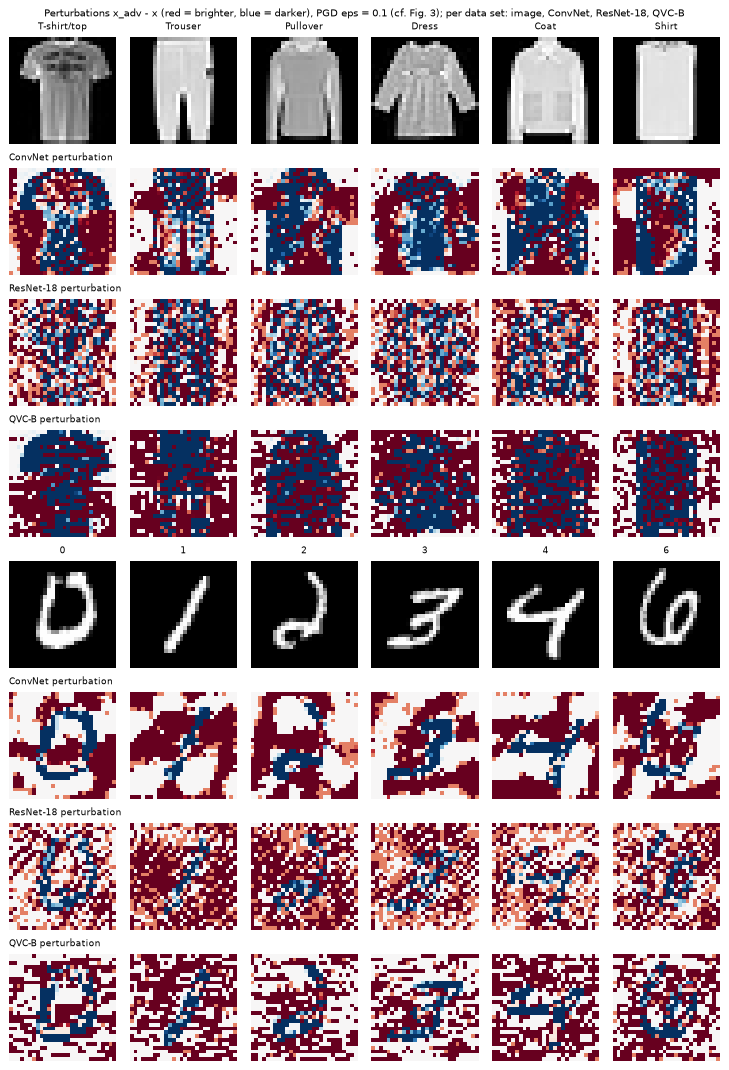

,dataset,crafted_on,eps,low_freq_power_fraction,alignment_with_class_shift,alignment_se,images_fooled
0,Fashion-MNIST,ConvNet,0.1,0.551,0.321,0.012,132
1,Fashion-MNIST,ResNet-18,0.1,0.291,0.185,0.014,150
2,Fashion-MNIST,QVC-B,0.1,0.343,0.227,0.012,150
3,Fashion-MNIST,random sign noise,0.1,0.224,NaN,NaN,0
4,MNIST,ConvNet,0.1,0.713,0.293,0.011,79
5,MNIST,ResNet-18,0.1,0.489,0.172,0.010,120
6,MNIST,QVC-B,0.1,0.480,0.219,0.008,143
7,MNIST,random sign noise,0.1,0.395,NaN,NaN,0


In [16]:
def lowfreq_frac(d, rad=4):
    Fp = np.abs(np.fft.fftshift(np.fft.fft2(d.reshape(IMG, IMG)))) ** 2; yy, xx = np.mgrid[:IMG, :IMG] - IMG // 2
    return float(Fp[np.hypot(yy, xx) <= rad].sum() / max(Fp.sum(), 1e-12))

PERT = {}
fig, axs = plt.subplots(2 * (1 + 3), 6, figsize=(8.2, 2 * 4 * 1.45 + 0.5))
rows = []
for k_ds, ds in enumerate(DATASETS):
    d = DATA[ds]; XT, YT = d["Xte"][:N_ATK], d["yte"][:N_ATK]; mu = torch.stack([d["Xtr"][d["ytr"] == k].mean(0) for k in range(N_CLASSES)])
    srcs = ["ConvNet", "ResNet-18", "QVC-B"]; g = torch.Generator().manual_seed(SEED)
    rnd = ((XT + EPS_PERT * torch.sign(torch.randn(XT.shape, generator=g))).clamp(0, 1) - XT)
    sel = [int(torch.nonzero(YT == k)[0, 0]) for k in (0, 1, 2, 3, 4, 6) if (YT == k).any()][:6]
    for i, j in enumerate(sel):
        axs[4 * k_ds, i].imshow(XT[j].reshape(IMG, IMG), cmap="gray"); axs[4 * k_ds, i].set_title(f"{SPECS[ds]['names'][int(YT[j])]}", fontsize=7); axs[4 * k_ds, i].axis("off")
    for r, src in enumerate(srcs):
        Xa = ADVX[(ds, "pgd", src, EPS_PERT)] if EPS_PERT in EPS_LIST else craft(FN[ds][src], XT, YT, EPS_PERT, PGD_STEPS, SEED)
        dl = Xa - XT
        for i, j in enumerate(sel):
            axs[4 * k_ds + 1 + r, i].imshow(dl[j].reshape(IMG, IMG), cmap="RdBu_r", vmin=-EPS_PERT, vmax=EPS_PERT); axs[4 * k_ds + 1 + r, i].axis("off")
            if i == 0: axs[4 * k_ds + 1 + r, i].set_title(f"{src} perturbation", fontsize=7, loc="left")
        with torch.no_grad():
            pred = predict_logits(FN[ds][src], Xa).argmax(1)
        ok = (pred != YT)
        lf = [lowfreq_frac(dl[i].numpy()) for i in range(len(dl))]
        if ok.any():
            tgt_dir = mu[pred[ok]] - mu[YT[ok]]
            cos = F.cosine_similarity(dl[ok], tgt_dir, dim=1)
            al, al_se = float(cos.mean()), float(cos.std() / math.sqrt(max(int(ok.sum()), 1)))
        else:
            al, al_se = float("nan"), float("nan")
        rows.append(dict(dataset=SPECS[ds]["title"], crafted_on=src, eps=EPS_PERT, low_freq_power_fraction=round(float(np.mean(lf)), 3), alignment_with_class_shift=round(al, 3), alignment_se=round(al_se, 3), images_fooled=int(ok.sum())))
        PERT[(ds, src)] = dict(lf=float(np.mean(lf)), align=al)
    rows.append(dict(dataset=SPECS[ds]["title"], crafted_on="random sign noise", eps=EPS_PERT, low_freq_power_fraction=round(float(np.mean([lowfreq_frac(rnd[i].numpy()) for i in range(len(rnd))])), 3),
                     alignment_with_class_shift=float("nan"), alignment_se=float("nan"), images_fooled=0))
plt.suptitle(f"Perturbations x_adv - x (red = brighter, blue = darker), PGD eps = {EPS_PERT} (cf. Fig. 3); per data set: image, ConvNet, ResNet-18, QVC-B", fontsize=8)
plt.tight_layout(); plt.show()
PERT_TABLE = pd.DataFrame(rows); display(PERT_TABLE)

## 6. Is the QVC's resistance to classical attacks real? An adaptive-attack audit (not in the paper)

The paper's headline is that attacks crafted on a ConvNet do not fool the QVC. That is a statement about a **transfer (black-box) threat model**. A defence is only credible if it also survives an attacker who adapts to it
(Athalye et al., "Obfuscated gradients give a false sense of security"). We therefore compare, for the same QVC-A and the same `eps`:

| attack on QVC-A | what the attacker knows |
|---|---|
| random sign noise | nothing (control: how much does *any* perturbation of this size hurt?) |
| PGD crafted on the ConvNet | the paper's "classical attack" (transfer) |
| PGD crafted on an **imitation** ConvNet trained only on the QVC-A's *predicted labels* of the training images | query access only (Papernot-style black box) |
| FGSM / PGD / strong PGD **through the QVC-A itself** | white box |
| strong PGD = margin loss, `ADAPT_STEPS` steps, `ADAPT_RESTARTS` restarts | adaptive white box (the standard check against gradient masking) |

Gradient-masking red flags (Athalye et al.): single-step beats iterative attacks, more steps/restarts do not lower the accuracy, transfer attacks beat white-box attacks, accuracy does not reach 0 at large `eps`, or the input gradient is exactly zero.
Because the QVC outputs are bounded in [-1, 1], its input gradients are small, but the signed-gradient attacks used here do not depend on their size.

Fashion-MNIST audit done [153 s]


MNIST audit done [413 s]


,dataset,median_grad_norm_QVC,median_grad_norm_ConvNet,min_grad_norm_QVC,images_with_zero_gradient_QVC,clone_agreement_with_QVC_on_test
0,Fashion-MNIST,0.802400,0.626248,0.345245,0,0.833
1,MNIST,1.121944,0.022691,0.347561,0,0.757


Accuracy (%) of QVC-A (clean accuracy of the same 150 images in the eps=0 column; 'ConvNet' row is a different model, shown for contrast):


,dataset,attack_on_QVC_A,eps=0.0,eps=0.1,eps=0.2,eps=0.3
0,Fashion-MNIST,clean / random sign noise,66.7,62.7,54.0,36.7
1,Fashion-MNIST,transfer: PGD on ConvNet,66.7,57.3,36.0,23.3
2,Fashion-MNIST,transfer: PGD on imitation ConvNet (queries only),66.7,39.3,17.3,8.0
3,Fashion-MNIST,white box: FGSM,66.7,2.7,0.0,0.0
4,Fashion-MNIST,white box: PGD-5,66.7,2.0,0.0,0.0
5,Fashion-MNIST,adaptive white box: margin PGD-10 x 2 restarts,NaN,2.0,0.0,NaN
6,Fashion-MNIST,ConvNet (for contrast): adaptive white box,NaN,11.3,0.0,NaN
7,MNIST,clean / random sign noise,69.3,67.3,55.3,38.0
8,MNIST,transfer: PGD on ConvNet,69.3,62.0,38.0,19.3
9,MNIST,transfer: PGD on imitation ConvNet (queries only),69.3,52.0,18.7,5.3


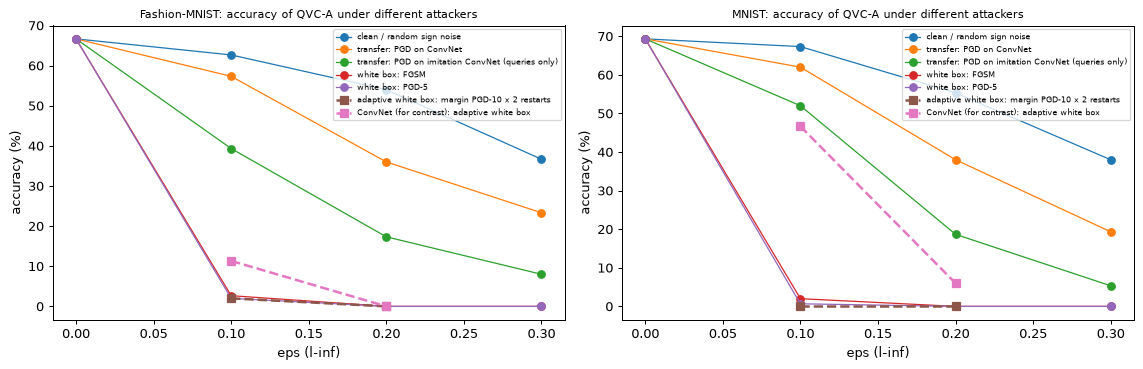

In [17]:
def input_grad_norm(fn, X, y, bs=50):
    out = []
    for s in range(0, len(X), bs):
        x = X[s:s + bs].clone().requires_grad_(True)
        gr, = torch.autograd.grad(F.cross_entropy(fn(x), y[s:s + bs], reduction="sum"), x); out.append(gr.flatten(1).norm(dim=1))
    return torch.cat(out)

AD = {}; ADIMG = {}; CLONE = {}; GRADS = []; t0 = time.time()
for ds in DATASETS:
    d = DATA[ds]; XT, YT = d["Xte"][:N_ATK], d["yte"][:N_ATK]; fnA = FN[ds]["QVC-A"]
    # imitation attack: a ConvNet trained on the labels that the QVC-A *predicts* for the training images (query access only)
    with torch.no_grad():
        yq = predict_logits(fnA, d["Xtr"]).argmax(1)
    torch.manual_seed(SEED); clone = train_net(ConvNet(), d["Xtr"], yq, CNN_EPOCHS, SEED + 1); CLONE[ds] = clone
    agree = float((predict_logits(clone, d["Xte"]).argmax(1) == predict_logits(fnA, d["Xte"]).argmax(1)).float().mean())
    # gradient diagnostics
    gq, gc = input_grad_norm(fnA, XT, YT), input_grad_norm(FN[ds]["ConvNet"], XT, YT)
    GRADS.append(dict(dataset=SPECS[ds]["title"], median_grad_norm_QVC=float(gq.median()), median_grad_norm_ConvNet=float(gc.median()), min_grad_norm_QVC=float(gq.min()),
                      images_with_zero_gradient_QVC=int((gq < 1e-12).sum()), clone_agreement_with_QVC_on_test=round(agree, 3)))
    gen = torch.Generator().manual_seed(SEED)
    for eps in EPS_LIST:
        AD[(ds, "clean / random sign noise", eps)] = acc_fn(fnA, (XT + eps * torch.sign(torch.randn(XT.shape, generator=gen))).clamp(0, 1), YT)
        AD[(ds, "transfer: PGD on ConvNet", eps)] = A(ds, "pgd", "ConvNet", "QVC-A", eps)
        Xc = craft(clone, XT, YT, eps, PGD_STEPS, SEED); AD[(ds, "transfer: PGD on imitation ConvNet (queries only)", eps)] = acc_fn(fnA, Xc, YT)
        AD[(ds, "white box: FGSM", eps)] = A(ds, "fgsm", "QVC-A", "QVC-A", eps)
        AD[(ds, f"white box: PGD-{PGD_STEPS}", eps)] = A(ds, "pgd", "QVC-A", "QVC-A", eps)
        if eps in EPS_ADAPT:
            Xs = craft(fnA, XT, YT, eps, ADAPT_STEPS, SEED + 5, loss="margin", restarts=ADAPT_RESTARTS); ADIMG[(ds, eps)] = Xs
            AD[(ds, f"adaptive white box: margin PGD-{ADAPT_STEPS} x {ADAPT_RESTARTS} restarts", eps)] = acc_fn(fnA, Xs, YT)
            Xs = craft(FN[ds]["ConvNet"], XT, YT, eps, ADAPT_STEPS, SEED + 5, loss="margin", restarts=ADAPT_RESTARTS)
            AD[(ds, "ConvNet (for contrast): adaptive white box", eps)] = acc_fn(FN[ds]["ConvNet"], Xs, YT)
    print(f"{SPECS[ds]['title']} audit done [{time.time() - t0:.0f} s]")
display(pd.DataFrame(GRADS))
rows = []
for ds in DATASETS:
    for lab in dict.fromkeys(k[1] for k in AD if k[0] == ds):
        rows.append(dict(dataset=SPECS[ds]["title"], attack_on_QVC_A=lab, **{f"eps={e}": (round(100 * AD[(ds, lab, e)], 1) if (ds, lab, e) in AD else np.nan) for e in EPS_LIST}))
AUDIT = pd.DataFrame(rows); print(f"Accuracy (%) of QVC-A (clean accuracy of the same {N_ATK} images in the eps=0 column; 'ConvNet' row is a different model, shown for contrast):"); display(AUDIT)
fig, axs = plt.subplots(1, len(DATASETS), figsize=(6.4 * len(DATASETS), 4.2), squeeze=False)
for ax, ds in zip(axs[0], DATASETS):
    for lab in dict.fromkeys(k[1] for k in AD if k[0] == ds):
        es = [e for e in EPS_LIST if (ds, lab, e) in AD]; ax.plot(es, [100 * AD[(ds, lab, e)] for e in es], "o-" if "adaptive" not in lab else "s--", label=lab, lw=2 if "adaptive white" in lab else 1)
    ax.set_title(f"{SPECS[ds]['title']}: accuracy of QVC-A under different attackers", fontsize=9); ax.set_xlabel("eps (l-inf)"); ax.set_ylabel("accuracy (%)"); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()

## 7. Adversarial training (claim C7, Fig. 4 and Fig. S11-S12)

Following the paper, each training batch is 50 % clean and 50 % adversarial images; the adversarial images are PGD with 3 steps at strength `eps`, recomputed on the model being trained. To fit a CPU budget we **fine-tune** the standard QVC-A
(and, for contrast, the ConvNet) for `ADV_EPOCHS` epochs instead of training from scratch. The paper's panels are reproduced for the data sets in `DATASETS_ADV`:

* (a) attack crafted on the standard ConvNet, applied to the standard and adversarially trained QVC-A (Fig. 4a);
* (b) attack crafted on the **standard QVC-A**, applied to the adversarially trained QVC-A copies (Fig. 4b);
* (c) the same attack applied to the ConvNet and its adversarially trained copies (Fig. 4c,d);
* (d) *new*: adaptive white-box attack (margin PGD) on each adversarially trained model **itself**, the only panel that measures real robustness.

In [18]:
def adv_finetune(model, fn, X, y, eps, epochs, lr, seed, bs=BATCH):
    """Fine-tune `model` (fn = pixels -> logits using that model) on 50 % clean + 50 % PGD-3 adversarial images at strength eps."""
    opt = torch.optim.Adam(model.parameters(), lr=lr); nst = epochs * ((len(X) + bs - 1) // bs)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=nst, pct_start=0.2); g = torch.Generator().manual_seed(seed); k = 0
    for ep in range(epochs):
        perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]; x, t = X[idx], y[idx]; h = len(idx) // 2
            xa = craft(fn, x[h:], t[h:], eps, 3, seed + k, bs=bs); k += 1
            loss = F.cross_entropy(fn(torch.cat([x[:h], xa])), torch.cat([t[:h], t[h:]])); opt.zero_grad(); loss.backward(); opt.step(); sch.step()
    return model

ADVM = {}; t0 = time.time()
for ds in DATASETS_ADV:
    d = DATA[ds]; ADVM[ds] = {}
    for eps in ADV_EPS:
        mq = copy.deepcopy(MODELS[ds]["QVC-A"]); adv_finetune(mq, PixelQVC(mq), d["Xtr"], d["ytr"], eps, ADV_EPOCHS, ADV_LR, SEED); mq.eval()
        mc = copy.deepcopy(MODELS[ds]["ConvNet"]); adv_finetune(mc, mc, d["Xtr"], d["ytr"], eps, ADV_EPOCHS, CNN_LR / 2, SEED); mc.eval()
        ADVM[ds][eps] = dict(q=mq, fq=PixelQVC(mq).eval(), c=mc)
        print(f"{SPECS[ds]['title']}: adversarially trained copies for eps={eps} [{time.time() - t0:.0f} s]")

Fashion-MNIST: adversarially trained copies for eps=0.1 [111 s]


Fashion-MNIST: adversarially trained copies for eps=0.2 [175 s]


Fashion-MNIST: adversarial-training evaluation done [281 s]


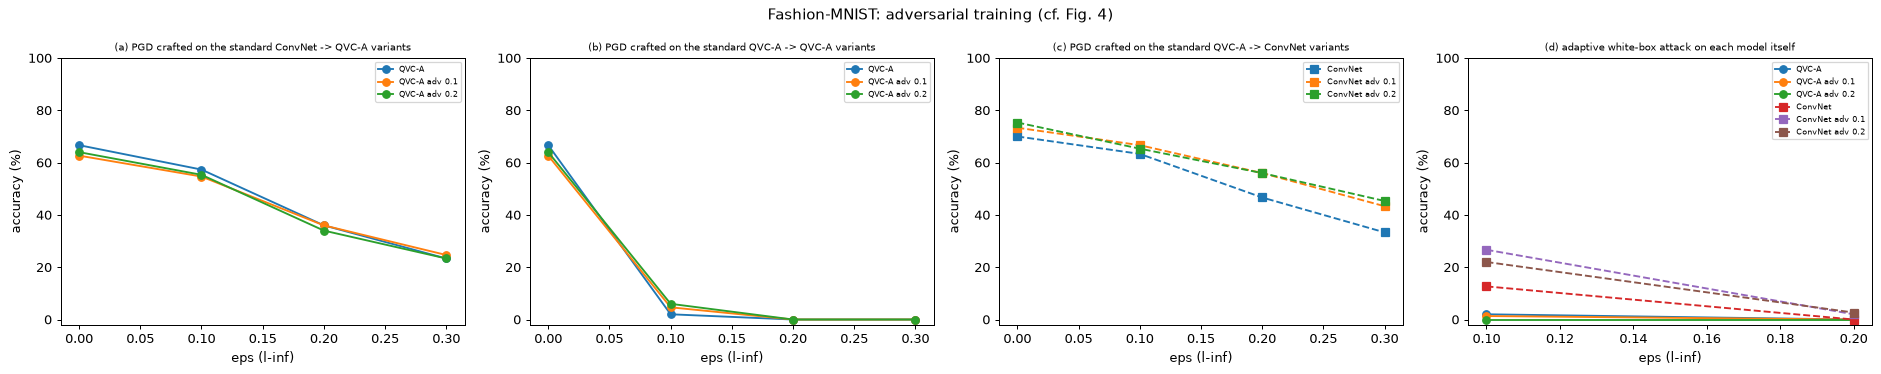

Fashion-MNIST: accuracy (%) per model; a = transfer from ConvNet, b = transfer from standard QVC-A, adaptive = white box on the model itself


,clean,a@0.1,a@0.2,b@0.1,b@0.2,adaptive@0.1,adaptive@0.2
model,,,,,,,
QVC-A,67.3,57.3,36.0,2.0,0.0,2.0,0.0
ConvNet,73.7,12.0,0.0,63.3,46.7,12.7,0.0
QVC-A adv 0.1,65.3,54.7,36.0,4.7,0.0,1.3,0.0
ConvNet adv 0.1,76.7,33.3,5.3,66.7,56.0,26.7,2.0
QVC-A adv 0.2,65.7,55.3,34.0,6.0,0.0,0.0,0.0
ConvNet adv 0.2,77.3,34.0,5.3,65.3,56.0,22.0,2.7


In [19]:
ADT = {}   # (ds, panel, model label, eps) -> accuracy
for ds in DATASETS_ADV:
    d = DATA[ds]; XT, YT = d["Xte"][:N_ATK], d["yte"][:N_ATK]
    models = {"QVC-A": FN[ds]["QVC-A"], "ConvNet": FN[ds]["ConvNet"]}
    for e_tr in ADV_EPS:
        models[f"QVC-A adv {e_tr}"] = ADVM[ds][e_tr]["fq"]; models[f"ConvNet adv {e_tr}"] = ADVM[ds][e_tr]["c"]
    for name, fn in models.items():
        ADT[(ds, "clean", name, 0.0)] = acc_fn(fn, d["Xte"], d["yte"])
        for eps in EPS_LIST:
            ADT[(ds, "a: attack on ConvNet", name, eps)] = acc_fn(fn, ADVX[(ds, "pgd", "ConvNet", eps)], YT)
            ADT[(ds, "b: attack on standard QVC-A", name, eps)] = acc_fn(fn, ADVX[(ds, "pgd", "QVC-A", eps)], YT)
        for eps in EPS_ADAPT:
            Xs = craft(fn, XT, YT, eps, ADAPT_STEPS, SEED + 9, loss="margin", restarts=ADAPT_RESTARTS); ADT[(ds, "d: adaptive attack on the model itself", name, eps)] = acc_fn(fn, Xs, YT)
    print(f"{SPECS[ds]['title']}: adversarial-training evaluation done [{time.time() - t0:.0f} s]")

def adt_plot(ds):
    fig, axs = plt.subplots(1, 4, figsize=(21, 4.2))
    qn = ["QVC-A"] + [f"QVC-A adv {e}" for e in ADV_EPS]; cn = ["ConvNet"] + [f"ConvNet adv {e}" for e in ADV_EPS]
    for ax, (panel, names, ttl, es) in zip(axs, [("a: attack on ConvNet", qn, "(a) PGD crafted on the standard ConvNet -> QVC-A variants", EPS_LIST),
                                                   ("b: attack on standard QVC-A", qn, "(b) PGD crafted on the standard QVC-A -> QVC-A variants", EPS_LIST),
                                                   ("b: attack on standard QVC-A", cn, "(c) PGD crafted on the standard QVC-A -> ConvNet variants", EPS_LIST),
                                                   ("d: adaptive attack on the model itself", qn + cn, "(d) adaptive white-box attack on each model itself", EPS_ADAPT)]):
        for n in names:
            ax.plot(es, [100 * ADT[(ds, panel, n, e)] for e in es], "o-" if n.startswith("QVC") else "s--", label=n)
        ax.set_title(ttl, fontsize=8); ax.set_xlabel("eps (l-inf)"); ax.set_ylabel("accuracy (%)"); ax.set_ylim(-2, 100); ax.legend(fontsize=6)
    plt.suptitle(f"{SPECS[ds]['title']}: adversarial training (cf. Fig. 4)"); plt.tight_layout(); plt.show()
for ds in DATASETS_ADV:
    adt_plot(ds)
    rows = []
    for name in dict.fromkeys(k[2] for k in ADT if k[0] == ds):
        r = dict(model=name, clean=round(100 * ADT[(ds, "clean", name, 0.0)], 1))
        for panel in ("a: attack on ConvNet", "b: attack on standard QVC-A"):
            r.update({f"{panel[0]}@{e}": round(100 * ADT[(ds, panel, name, e)], 1) for e in EPS_ADAPT})
        r.update({f"adaptive@{e}": round(100 * ADT[(ds, "d: adaptive attack on the model itself", name, e)], 1) for e in EPS_ADAPT})
        rows.append(r)
    print(f"{SPECS[ds]['title']}: accuracy (%) per model; a = transfer from ConvNet, b = transfer from standard QVC-A, adaptive = white box on the model itself"); display(pd.DataFrame(rows).set_index("model"))

## 8. Attack detection by classifier disagreement (claim C9, Fig. 5)

The paper's detector flags an input as attacked if a classical network (ConvNet or ResNet-18) and the deeper QVC predict **different labels**. It tests `N_DET` clean and `N_DET` attacked images ("arbitrary attack strengths and types") and reports,
for Fashion-MNIST with QVC500, 227 false positives and 736 true positives for ConvNet + QVC (out of 1 000 each), and 234 and 795 for ResNet + QVC. The attacked images here are FGSM or PGD with `eps` drawn at random from `DET_EPS`.

Three attackers are evaluated: **(i)** the paper's reading: the attack is crafted on the classical network of the pair; **(ii)** the attack is crafted on the QVC (paper: such attacks also fool classical networks, so the detector should fail);
**(iii)** an *adaptive* attacker who knows the detector and runs a **targeted** PGD on both networks at once towards the label `(y + 1) mod 10`, so that they agree on the wrong label.
Counts are scaled to 1 000 images for comparison with the paper.

In [20]:
class Joint(nn.Module):
    """Both networks of the detector as one model: the sum of the log-probabilities."""
    def __init__(self, a, b):
        super().__init__(); self.a, self.b = a, b
    def forward(self, x):
        return F.log_softmax(self.a(x), 1) + F.log_softmax(self.b(x), 1)

def attack_mixed(fn, X, y, seed, target=None):
    rg = np.random.default_rng(seed); kinds = rg.choice(["fgsm", "pgd"], len(X)); epss = rg.choice(DET_EPS, len(X)); out = X.clone()
    for kind in ("fgsm", "pgd"):
        for eps in DET_EPS:
            idx = torch.as_tensor(np.flatnonzero((kinds == kind) & (epss == eps)), dtype=torch.long)
            if len(idx):
                out[idx] = craft(fn, X[idx], y[idx], float(eps), PGD_STEPS, seed + int(100 * eps), kind=kind, target=None if target is None else target[idx])
    return out

DET = []; t0 = time.time()
for ds in DATASETS:
    d = DATA[ds]; X, y = d["Xte"][:N_DET], d["yte"][:N_DET]; fq = FN[ds]["QVC-B"]; tgt = (y + 1) % N_CLASSES
    for cname in ("ConvNet", "ResNet-18"):
        fc = FN[ds][cname]; pc, pq = predict_logits(fc, X).argmax(1), predict_logits(fq, X).argmax(1)
        fp = int((pc != pq).sum())
        for scen, Xa, extra in [("(i) attack on " + cname, attack_mixed(fc, X, y, SEED), ""), ("(ii) attack on QVC-B", attack_mixed(fq, X, y, SEED + 1), ""),
                                ("(iii) adaptive joint targeted attack", attack_mixed(Joint(fc, fq), X, y, SEED + 2, target=tgt), "")]:
            ac, aq = predict_logits(fc, Xa).argmax(1), predict_logits(fq, Xa).argmax(1)
            tp = int((ac != aq).sum()); evaded = int(((ac == aq) & (ac != y)).sum())
            DET.append(dict(dataset=ds, pair=f"{cname} + QVC-B", scenario=scen, false_pos_per_1000=round(1000 * fp / N_DET), true_pos_per_1000=round(1000 * tp / N_DET),
                            classical_fooled=round(1000 * float((ac != y).float().mean())), qvc_fooled=round(1000 * float((aq != y).float().mean())), both_agree_on_wrong_label_per_1000=round(1000 * evaded / N_DET)))
    print(f"{SPECS[ds]['title']} detector done [{time.time() - t0:.0f} s]")
DET = pd.DataFrame(DET); display(DET)
print("paper, Fashion-MNIST, QVC500 (per 1000): ConvNet + QVC: FP 227, TP 736;  ResNet + QVC: FP 234, TP 795")

Fashion-MNIST detector done [53 s]


MNIST detector done [98 s]


,dataset,pair,scenario,false_pos_per_1000,true_pos_per_1000,classical_fooled,qvc_fooled,both_agree_on_wrong_label_per_1000
0,fmnist,ConvNet + QVC-B,(i) attack on ConvNet,285,580,855,550,285
1,fmnist,ConvNet + QVC-B,(ii) attack on QVC-B,285,725,505,950,225
2,fmnist,ConvNet + QVC-B,(iii) adaptive joint targeted attack,285,510,665,720,310
3,fmnist,ResNet-18 + QVC-B,(i) attack on ResNet-18,300,830,980,425,155
4,fmnist,ResNet-18 + QVC-B,(ii) attack on QVC-B,300,820,580,950,130
5,fmnist,ResNet-18 + QVC-B,(iii) adaptive joint targeted attack,300,835,915,470,110
6,mnist,ConvNet + QVC-B,(i) attack on ConvNet,270,570,650,545,170
7,mnist,ConvNet + QVC-B,(ii) attack on QVC-B,270,880,260,940,60
8,mnist,ConvNet + QVC-B,(iii) adaptive joint targeted attack,270,575,530,725,215
9,mnist,ResNet-18 + QVC-B,(i) attack on ResNet-18,270,600,740,460,185


paper, Fashion-MNIST, QVC500 (per 1000): ConvNet + QVC: FP 227, TP 736;  ResNet + QVC: FP 234, TP 795


## 9. Noise (claim C10, Fig. S14)

* **Depolarising noise.** In the paper's description the state is replaced by the maximally mixed state with probability `p`. Then every expectation value is multiplied by `(1 - p)`; the argmax cannot change. We show this identity with the trained QVC-A
  (it is exact for the global channel, not a simulation of a gate-level depolarising model).
* **Bit-flip noise.** After every layer each qubit is flipped (Pauli X) with probability `p` (CHOICE: per layer, not per gate). The mixed state is sampled with `NOISE_K` Monte-Carlo trajectories per image and the expectation values are averaged.
* **Amplitude damping** needs non-unitary trajectories or density matrices and is not simulated here.

p                                             0.000  0.001  0.005  0.010  0.100  0.500  0.900
dataset noise                                                                                
fmnist  bit flip (Monte Carlo)                0.717  0.717  0.717  0.633    NaN    NaN    NaN
        global depolarising (exact identity)  0.717    NaN    NaN    NaN  0.717  0.717  0.717
mnist   bit flip (Monte Carlo)                0.617  0.583  0.583  0.600    NaN    NaN    NaN
        global depolarising (exact identity)  0.617    NaN    NaN    NaN  0.617  0.617  0.617

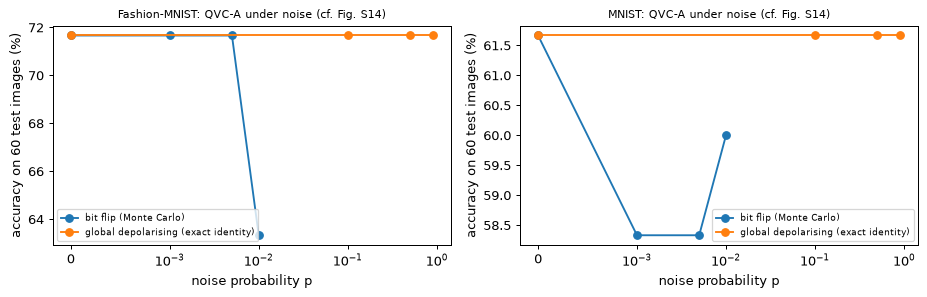

In [21]:
@torch.no_grad()
def qvc_bitflip(model, psi, p, K, seed):
    """<Z_k> of the QVC under independent bit flips (probability p per qubit and layer), averaged over K Monte-Carlo trajectories per image."""
    B, h = psi.shape[0], model.nq // 2; g = torch.Generator().manual_seed(seed)
    U = rot_mats(model.theta); Ma = kron_group(U[:, :h]); MbT = kron_group(U[:, h:]).transpose(-1, -2); cz = model.cz.reshape(2 ** h, 2 ** (model.nq - h))
    s = psi.to(CDT).repeat_interleave(K, 0); idx = torch.arange(2 ** model.nq); w = 2 ** (model.nq - 1 - torch.arange(model.nq))
    for l in range(model.L):
        s = (torch.matmul(torch.matmul(Ma[l], s.reshape(B * K, 2 ** h, -1)), MbT[l]) * cz).reshape(B * K, -1)
        if p > 0:
            mask = ((torch.rand(B * K, model.nq, generator=g) < p).long() * w).sum(1); s = torch.gather(s, 1, idx[None, :] ^ mask[:, None])
    return ((s.abs() ** 2) @ model.zs.T).reshape(B, K, -1).mean(1)

NOISE = []
for ds in DATASETS:
    d = DATA[ds]; m = MODELS[ds]["QVC-A"]; psi = amp_encode(d["Xte"][:N_NOISE]); yy = d["yte"][:N_NOISE]
    clean = float((m.expvals(psi).argmax(1) == yy).float().mean())
    for p in (0.0, 0.1, 0.5, 0.9):
        NOISE.append(dict(dataset=ds, noise="global depolarising (exact identity)", p=p, accuracy=float(((1 - p) ** L_A * m.expvals(psi)).argmax(1).eq(yy).float().mean())))
    for p in BITFLIP_P:
        NOISE.append(dict(dataset=ds, noise="bit flip (Monte Carlo)", p=p, accuracy=float((qvc_bitflip(m, psi, p, NOISE_K if p > 0 else 1, SEED).argmax(1) == yy).float().mean())))
    assert abs(NOISE[-len(BITFLIP_P)]["accuracy"] - clean) < 1e-9, "p = 0 must reproduce the noiseless accuracy"
NOISE = pd.DataFrame(NOISE); display(NOISE.pivot_table(index=["dataset", "noise"], columns="p", values="accuracy").round(3))
fig, axs = plt.subplots(1, len(DATASETS), figsize=(5.2 * len(DATASETS), 3.4), squeeze=False)
for ax, ds in zip(axs[0], DATASETS):
    for nz, g in NOISE[NOISE.dataset == ds].groupby("noise"):
        ax.plot(g["p"], 100 * g["accuracy"], "o-", label=nz)
    ax.set_xscale("symlog", linthresh=1e-3); ax.set_xlabel("noise probability p"); ax.set_ylabel(f"accuracy on {N_NOISE} test images (%)"); ax.set_title(f"{SPECS[ds]['title']}: QVC-A under noise (cf. Fig. S14)", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 10. Paper versus this notebook: a verdict per claim

Rules (stated before looking at the numbers): *retention* = accuracy under attack / clean accuracy of the same model on the same images; "eps_hi" = 0.2; a claim that holds on only some data sets is "partially reproduced".
Printed counts (the detector) are compared with the paper within 2 percentage points (20 per 1000), as everywhere in this project; qualitative claims use the thresholds written in the table.

In [22]:
EH = 0.2
def ret(ds, kind, src, tgt, e=EH): return A(ds, kind, src, tgt, e) / max(A(ds, kind, src, tgt, 0.0), 1e-9)
def verdict(flags, detail=None):
    v = list(flags.values())
    return "reproduced" if all(v) else ("partially reproduced (" + ", ".join(k for k, f in flags.items() if f) + " only)" if any(v) else "not reproduced")
def fmt(f): return "; ".join(f"{SPECS[ds]['title']}: {f(ds)}" for ds in DATASETS)

CL = []
CL.append(("C1 classical transfer: ConvNet attack lowers ResNet-18 accuracy", "ResNet falls 'rather rapidly' (Fig. 2a-d)", fmt(lambda ds: f"ResNet retention {ret(ds,'pgd','ConvNet','ResNet-18'):.2f} at eps {EH}"),
           verdict({ds: ret(ds, "pgd", "ConvNet", "ResNet-18") < 0.7 for ds in DATASETS}), "retention < 0.7"))
CL.append(("C2 QVC resists the ConvNet attack", "QVC200 keeps 'reasonable accuracies' for eps >= 0.2", fmt(lambda ds: f"QVC-A retention {ret(ds,'pgd','ConvNet','QVC-A'):.2f} vs ResNet {ret(ds,'pgd','ConvNet','ResNet-18'):.2f}, ConvNet {ret(ds,'pgd','ConvNet','ConvNet'):.2f}"),
           verdict({ds: ret(ds, "pgd", "ConvNet", "QVC-A") >= 0.5 and ret(ds, "pgd", "ConvNet", "QVC-A") > ret(ds, "pgd", "ConvNet", "ResNet-18") for ds in DATASETS}), "QVC retention >= 0.5 and > ResNet retention"))
CL.append(("C3 QVC is vulnerable to a white-box attack", "accuracy of QVC200 'falls rapidly' (Fig. 2e-h)", fmt(lambda ds: f"QVC-A white-box retention {ret(ds,'pgd','QVC-A','QVC-A'):.2f}"),
           verdict({ds: ret(ds, "pgd", "QVC-A", "QVC-A") < 0.2 for ds in DATASETS}), "retention < 0.2"))
CL.append(("C4 QVC-to-QVC transfer, weaker than classical-to-classical", "QVC200 attack transfers to QVC500, 'relatively weak'", fmt(lambda ds: f"QVC-B retention {ret(ds,'pgd','QVC-A','QVC-B'):.2f} vs ResNet-from-ConvNet {ret(ds,'pgd','ConvNet','ResNet-18'):.2f}"),
           verdict({ds: ret(ds, "pgd", "QVC-A", "QVC-B") < 0.8 and ret(ds, "pgd", "QVC-A", "QVC-B") > ret(ds, "pgd", "ConvNet", "ResNet-18") for ds in DATASETS}), "transfers (retention < 0.8) but retention > classical case"))
CL.append(("C5 QVC attacks fool the classical networks", "classical networks fail against QVC200 attacks", fmt(lambda ds: f"ConvNet {ret(ds,'pgd','QVC-A','ConvNet'):.2f}, ResNet {ret(ds,'pgd','QVC-A','ResNet-18'):.2f}"),
           verdict({ds: ret(ds, "pgd", "QVC-A", "ConvNet") < 0.5 and ret(ds, "pgd", "QVC-A", "ResNet-18") < 0.6 for ds in DATASETS}), "ConvNet retention < 0.5 and ResNet < 0.6"))
CL.append(("C6 QVC perturbations carry more structure", "QVC perturbations meaningful, classical ones high-frequency noise (Fig. 3)",
           fmt(lambda ds: f"low-freq power QVC-B {PERT[(ds,'QVC-B')]['lf']:.2f} vs ConvNet {PERT[(ds,'ConvNet')]['lf']:.2f}/ResNet {PERT[(ds,'ResNet-18')]['lf']:.2f}; alignment {PERT[(ds,'QVC-B')]['align']:.2f} vs {PERT[(ds,'ConvNet')]['align']:.2f}/{PERT[(ds,'ResNet-18')]['align']:.2f}"),
           verdict({ds: PERT[(ds, "QVC-B")]["lf"] > max(PERT[(ds, "ConvNet")]["lf"], PERT[(ds, "ResNet-18")]["lf"]) and PERT[(ds, "QVC-B")]["align"] > max(PERT[(ds, "ConvNet")]["align"], PERT[(ds, "ResNet-18")]["align"]) for ds in DATASETS}), "QVC higher on both measures"))
CL.append(("C8 depth changes little", "QVC500 vs QVC200: limited effect (Fig. S2, S15)", fmt(lambda ds: f"clean {100*A(ds,'pgd','ConvNet','QVC-A',0.0):.0f} vs {100*A(ds,'pgd','ConvNet','QVC-B',0.0):.0f} %, retention {ret(ds,'pgd','ConvNet','QVC-A'):.2f} vs {ret(ds,'pgd','ConvNet','QVC-B'):.2f}"),
           verdict({ds: abs(A(ds, "pgd", "ConvNet", "QVC-A", 0.0) - A(ds, "pgd", "ConvNet", "QVC-B", 0.0)) < 0.08 and abs(ret(ds, "pgd", "ConvNet", "QVC-A") - ret(ds, "pgd", "ConvNet", "QVC-B")) < 0.15 for ds in DATASETS}), "clean within 8 points and retention within 0.15"))
if DATASETS_ADV:
    g = lambda ds, p, n, e: ADT[(ds, p, n, e)]
    qa = lambda ds: [f"QVC-A adv {e}" for e in ADV_EPS]; ca = lambda ds: [f"ConvNet adv {e}" for e in ADV_EPS]
    CL.append(("C7a adversarial training barely helps vs classical attacks", "negligible change (Fig. 4a,c)", "; ".join(f"{SPECS[ds]['title']}: gain at eps 0.2 " + ", ".join(f"{100*(g(ds,'a: attack on ConvNet',n,0.2)-g(ds,'a: attack on ConvNet','QVC-A',0.2)):+.0f}" for n in qa(ds)) + " points" for ds in DATASETS_ADV),
               verdict({ds: max(g(ds, "a: attack on ConvNet", n, 0.2) - g(ds, "a: attack on ConvNet", "QVC-A", 0.2) for n in qa(ds)) < 0.10 for ds in DATASETS_ADV}), "max gain < 10 points"))
    CL.append(("C7b adversarial training helps vs QVC attacks (transfer from standard QVC)", "accuracy improves, not fully restored (Fig. 4b,d)", "; ".join(f"{SPECS[ds]['title']}: gain at eps 0.2 " + ", ".join(f"{100*(g(ds,'b: attack on standard QVC-A',n,0.2)-g(ds,'b: attack on standard QVC-A','QVC-A',0.2)):+.0f}" for n in qa(ds)) + " points" for ds in DATASETS_ADV),
               verdict({ds: max(g(ds, "b: attack on standard QVC-A", n, 0.2) - g(ds, "b: attack on standard QVC-A", "QVC-A", 0.2) for n in qa(ds)) >= 0.10 for ds in DATASETS_ADV}), "max gain >= 10 points"))
    CL.append(("C7c adversarial training keeps clean accuracy", "no considerable reduction for QVCs", "; ".join(f"{SPECS[ds]['title']}: clean {100*g(ds,'clean','QVC-A',0.0):.1f} -> " + ", ".join(f"{100*g(ds,'clean',n,0.0):.1f}" for n in qa(ds)) for ds in DATASETS_ADV),
               verdict({ds: min(g(ds, "clean", n, 0.0) for n in qa(ds)) >= g(ds, "clean", "QVC-A", 0.0) - 0.05 for ds in DATASETS_ADV}), "drop < 5 points"))
    CL.append(("C7d adversarial training works for the ConvNet", "classical networks 'exhibit high accuracy when adversarially trained' (Fig. 4c,d)", "; ".join(f"{SPECS[ds]['title']}: ConvNet vs QVC-A attack at eps 0.2: " + f"{100*g(ds,'b: attack on standard QVC-A','ConvNet',0.2):.0f} -> " + ", ".join(f"{100*g(ds,'b: attack on standard QVC-A',n,0.2):.0f}" for n in ca(ds)) + " %" for ds in DATASETS_ADV),
               verdict({ds: max(g(ds, "b: attack on standard QVC-A", n, 0.2) for n in ca(ds)) - g(ds, "b: attack on standard QVC-A", "ConvNet", 0.2) >= 0.10 for ds in DATASETS_ADV}), "gain >= 10 points"))
# detector
dsd = "fmnist"; dd = DET[(DET.dataset == dsd)]
for pair, pfp, ptp in (("ConvNet + QVC-B", 227, 736), ("ResNet-18 + QVC-B", 234, 795)):
    r = dd[(dd.pair == pair) & (dd.scenario.str.startswith("(i)"))].iloc[0]
    ok = abs(r.false_pos_per_1000 - pfp) <= 20 and abs(r.true_pos_per_1000 - ptp) <= 20
    CL.append((f"C9 detector {pair} (Fashion-MNIST)", f"FP {pfp}, TP {ptp} per 1000", f"FP {r.false_pos_per_1000}, TP {r.true_pos_per_1000}", "reproduced" if ok else ("not reached (FP gap %+d, TP gap %+d per 1000)" % (r.false_pos_per_1000 - pfp, r.true_pos_per_1000 - ptp)), "within 20 per 1000"))
nz = NOISE
CL.append(("C10a depolarising noise leaves accuracy unchanged", "independent of noise strength", "identity (1-p)*<Z>: accuracy " + ", ".join(f"{100*v:.1f}" for v in nz[(nz.noise.str.startswith('global')) & (nz.dataset == DATASETS[0])].accuracy), "reproduced (analytic, global channel)" if nz[nz.noise.str.startswith("global")].groupby("dataset").accuracy.nunique().max() == 1 else "not reproduced", "accuracy constant in p"))
bf = nz[nz.noise.str.startswith("bit")]
CL.append(("C10b bit flips reduce accuracy only slightly", "slight reduction at 0.5 %", "; ".join(f"{SPECS[ds]['title']}: " + " / ".join(f"{100*bf[(bf.dataset==ds)&(bf.p==p)].accuracy.iloc[0]:.0f}" for p in BITFLIP_P) + " % at p=" + "/".join(str(p) for p in BITFLIP_P) for ds in DATASETS),
           verdict({ds: bf[(bf.dataset == ds) & (bf.p == 0.005)].accuracy.iloc[0] >= bf[(bf.dataset == ds) & (bf.p == 0.0)].accuracy.iloc[0] - 0.10 for ds in DATASETS}), "drop at p = 0.005 below 10 points (note: per layer here, not per gate)"))
CL.append(("C10c amplitude damping destroys accuracy", "severe impact", "not simulated", "cannot be checked", "-"))
CL.append(("C0 CIFAR-10 / Celeb-A (12 qubits) results", "Fig. 2 a-h, S2", "not run (no small public mirror)", "cannot be checked", "-"))
CL.append(("C0 AutoAttack results", "Fig. S6", "AutoAttack not available; margin-loss PGD used instead (section 6)", "cannot be checked", "-"))
CLAIMS = pd.DataFrame(CL, columns=["claim", "paper", "this notebook", "verdict", "rule"])
with pd.option_context("display.max_colwidth", 200): display(CLAIMS)

,claim,paper,this notebook,verdict,rule
0,C1 classical transfer: ConvNet attack lowers ResNet-18 accuracy,ResNet falls 'rather rapidly' (Fig. 2a-d),Fashion-MNIST: ResNet retention 0.45 at eps 0.2; MNIST: ResNet retention 0.52 at eps 0.2,reproduced,retention < 0.7
1,C2 QVC resists the ConvNet attack,QVC200 keeps 'reasonable accuracies' for eps >= 0.2,"Fashion-MNIST: QVC-A retention 0.54 vs ResNet 0.45, ConvNet 0.00; MNIST: QVC-A retention 0.55 vs ResNet 0.52, ConvNet 0.07",reproduced,QVC retention >= 0.5 and > ResNet retention
2,C3 QVC is vulnerable to a white-box attack,accuracy of QVC200 'falls rapidly' (Fig. 2e-h),Fashion-MNIST: QVC-A white-box retention 0.00; MNIST: QVC-A white-box retention 0.00,reproduced,retention < 0.2
3,"C4 QVC-to-QVC transfer, weaker than classical-to-classical","QVC200 attack transfers to QVC500, 'relatively weak'",Fashion-MNIST: QVC-B retention 0.40 vs ResNet-from-ConvNet 0.45; MNIST: QVC-B retention 0.55 vs ResNet-from-ConvNet 0.52,partially reproduced (mnist only),transfers (retention < 0.8) but retention > classical case
4,C5 QVC attacks fool the classical networks,classical networks fail against QVC200 attacks,"Fashion-MNIST: ConvNet 0.67, ResNet 0.36; MNIST: ConvNet 0.82, ResNet 0.59",not reproduced,ConvNet retention < 0.5 and ResNet < 0.6
5,C6 QVC perturbations carry more structure,"QVC perturbations meaningful, classical ones high-frequency noise (Fig. 3)",Fashion-MNIST: low-freq power QVC-B 0.34 vs ConvNet 0.55/ResNet 0.29; alignment 0.23 vs 0.32/0.18; MNIST: low-freq power QVC-B 0.48 vs ConvNet 0.71/ResNet 0.49; alignment 0.22 vs 0.29/0.17,not reproduced,QVC higher on both measures
6,C8 depth changes little,"QVC500 vs QVC200: limited effect (Fig. S2, S15)","Fashion-MNIST: clean 67 vs 69 %, retention 0.54 vs 0.43; MNIST: clean 69 vs 73 %, retention 0.55 vs 0.53",reproduced,clean within 8 points and retention within 0.15
7,C7a adversarial training barely helps vs classical attacks,"negligible change (Fig. 4a,c)","Fashion-MNIST: gain at eps 0.2 +0, -2 points",reproduced,max gain < 10 points
8,C7b adversarial training helps vs QVC attacks (transfer from standard QVC),"accuracy improves, not fully restored (Fig. 4b,d)","Fashion-MNIST: gain at eps 0.2 +0, +0 points",not reproduced,max gain >= 10 points
9,C7c adversarial training keeps clean accuracy,no considerable reduction for QVCs,"Fashion-MNIST: clean 67.3 -> 65.3, 65.7",reproduced,drop < 5 points


In [23]:
# The audit of section 6 in numbers: does the paper's robustness survive an adaptive attacker?
rows = []
for ds in DATASETS:
    g0 = lambda lab, e: AD[(ds, lab, e)]; ew = max(EPS_ADAPT)
    rows.append(dict(dataset=SPECS[ds]["title"], eps=ew, clean=round(100 * AD[(ds, "clean / random sign noise", 0.0)], 1), random_noise=round(100 * g0("clean / random sign noise", ew), 1),
                     transfer_from_ConvNet=round(100 * g0("transfer: PGD on ConvNet", ew), 1), transfer_from_imitation=round(100 * g0("transfer: PGD on imitation ConvNet (queries only)", ew), 1),
                     white_box_FGSM=round(100 * g0("white box: FGSM", ew), 1), white_box_PGD=round(100 * g0(f"white box: PGD-{PGD_STEPS}", ew), 1),
                     adaptive_white_box=round(100 * g0(f"adaptive white box: margin PGD-{ADAPT_STEPS} x {ADAPT_RESTARTS} restarts", ew), 1)))
AUD = pd.DataFrame(rows); print("QVC-A accuracy (%) at the largest adaptive strength:"); display(AUD)
for ds in DATASETS:
    r = AUD[AUD.dataset == SPECS[ds]["title"]].iloc[0]
    print(f"{SPECS[ds]['title']}: transfer-only 'robustness' {r.transfer_from_ConvNet:.0f} % -> adaptive white box {r.adaptive_white_box:.0f} %;  random noise alone {r.random_noise:.0f} %;  imitation attack {r.transfer_from_imitation:.0f} %")
    print("   gradient-masking checks:",
          "strong attack <= PGD:", r.adaptive_white_box <= r.white_box_PGD + 2, "| PGD <= FGSM:", r.white_box_PGD <= r.white_box_FGSM + 2, "| white box < transfer:", r.adaptive_white_box < r.transfer_from_ConvNet,
          "| zero-gradient images:", GRADS[DATASETS.index(ds)]["images_with_zero_gradient_QVC"])
print("Control (low-capacity classical models under the same ConvNet attack, retention at eps %.1f):" % EH)
display(pd.DataFrame({ds: {t: round(ret(ds, "pgd", "ConvNet", t), 2) for t in ("QVC-A", "QVC-B", "LogReg", "MLP-64", "ResNet-18", "ConvNet", "SVC(amp)", "RF(amp)")} for ds in DATASETS}))

QVC-A accuracy (%) at the largest adaptive strength:


,dataset,eps,clean,random_noise,transfer_from_ConvNet,transfer_from_imitation,white_box_FGSM,white_box_PGD,adaptive_white_box
0,Fashion-MNIST,0.2,66.7,54.0,36.0,17.3,0.0,0.0,0.0
1,MNIST,0.2,69.3,55.3,38.0,18.7,0.0,0.0,0.0


Fashion-MNIST: transfer-only 'robustness' 36 % -> adaptive white box 0 %;  random noise alone 54 %;  imitation attack 17 %
   gradient-masking checks: strong attack <= PGD: True | PGD <= FGSM: True | white box < transfer: True | zero-gradient images: 0
MNIST: transfer-only 'robustness' 38 % -> adaptive white box 0 %;  random noise alone 55 %;  imitation attack 19 %
   gradient-masking checks: strong attack <= PGD: True | PGD <= FGSM: True | white box < transfer: True | zero-gradient images: 0
Control (low-capacity classical models under the same ConvNet attack, retention at eps 0.2):


,fmnist,mnist
QVC-A,0.54,0.55
QVC-B,0.43,0.53
LogReg,0.33,0.35
MLP-64,0.40,0.35
ResNet-18,0.45,0.52
ConvNet,0.00,0.07
SVC(amp),0.44,0.43
RF(amp),0.26,0.15


## 11. Reading the paper critically

﻿The numbers below are from the committed `FAST_MODE = True` run (1 000 training images, QVC-A with 10 and QVC-B with 20 layers instead of 200 and 500, 150 attacked images, a 2-epoch adversarial fine-tuning); the paper's own figures are not tabulated, so every comparison is qualitative.

**What was reproduced.** (i) The QVC is as vulnerable as any network to a white-box attack: PGD at eps = 0.1 leaves QVC-A at 2 % (Fashion-MNIST) and 0.7 % (MNIST), and the margin-loss adaptive attack gives 0 % (C3, section 6). (ii) Attacks crafted on the ConvNet transfer to every other model, and the QVC keeps a bit more of its accuracy than the ResNet-18 (retention 0.54 / 0.55 versus 0.45 / 0.52 at eps = 0.2; C2). (iii) The depth of the QVC changes little (C8). (iv) Adversarial fine-tuning does not change the QVC against a ConvNet attack and does not reduce its clean accuracy (C7a, C7c). (v) Bit-flip noise of 0.5 % per layer leaves the accuracy unchanged and depolarising noise cannot change an argmax (C10a,b).

**What was not reproduced, and why one should hesitate to read it as a refutation.** The paper's strong claims are about large QVCs (200-1000 layers) trained on 60 000 images; ours are 10-20 layers on 1 000 images, so the QVC's clean accuracy (67-74 %) is below the classical networks on MNIST (91-93 %). The detector counts differ for that reason (ConvNet + QVC-B on Fashion-MNIST: 285 false and 580 true positives per 1 000 against the paper's 227 and 736; ResNet + QVC-B: 300 and 830 against 234 and 795): the false-positive rate of a disagreement detector is bounded below by the classifiers' own error. The adversarial training (C7b, C7d) was a 2-epoch fine-tuning of 1 000 images, far weaker than the paper's from-scratch training, so a null effect there says little. The perturbation claim (C6) is not supported by our two simple measures: the ConvNet perturbations are at least as low-frequency (0.55 / 0.71 of the Fourier power) as the QVC-B perturbations (0.34 / 0.48), and their alignment with the "move towards the wrong class" direction is higher (0.32 / 0.29 against 0.23 / 0.22); these measures do not capture the human impression of Fig. 3 (sleeves added to a T-shirt), so the claim is "not reproduced by these metrics", not disproved. CIFAR-10, Celeb-A and AutoAttack were not run.

**Is the headline "quantum advantage in robustness" supported?** Our controls say: not by this evidence.
1. *One-way transfer is not special to the QVC.* A ResNet-18 attack barely fools the ConvNet (retention 0.88 / 0.87) and only partly the QVC-A (0.77 / 0.71), so transfer between different models is asymmetric and incomplete even among classical models. The QVC's retention under the ConvNet attack (0.54 / 0.55) is similar to that of the ResNet-18 (0.45 / 0.52) and the RBF-SVM on the amplitudes (0.44 / 0.43), and only a little better than the MLP (0.40 / 0.35) and the logistic regression (0.33 / 0.35).
2. *The resistance disappears as soon as the attacker adapts.* An imitation ConvNet trained only on the labels the QVC predicts for the training images (agreement with the QVC on test images 83 % / 76 %) lowers QVC-A from 36 % / 38 % (ConvNet transfer) to 17 % / 19 % at eps = 0.2, and a white-box attack takes it to 0 %. No gradient masking was found (no image with zero input gradient; the strong attack is not weaker than PGD, which is not weaker than FGSM; white box beats every transfer attack), so the QVC is simply not robust; its apparent resistance is a feature of the weak threat model, exactly as Athalye et al. warn.
3. *The disagreement detector is an easy target.* A joint targeted attack on both networks of the pair lowers the detection rate (ConvNet + QVC-B: 580 to 510 per 1 000 on Fashion-MNIST, 570 to 575 on MNIST with only 10 steps) and makes 310 / 215 per 1 000 images agree on a wrong label; a stronger optimiser would do more.
4. *Random noise alone is already harmful*: at eps = 0.2 the QVC-A falls to 54 % under random sign noise, and amplitude encoding is norm-sensitive.
5. *The QVC is a classical-looking function*: with amplitude encoding the output is a normalised quadratic form of the pixels, `x^T U^T Z_k U x / ||x||^2`; a classical model of that form is the fair control (exercise 3).

**Other caveats.** One training seed per model; 150 attacked images (about +-4 points standard error); the PGD step number, learning rates, initialisation, logit scale and the CZ/rotation details are our choices; the Fashion-MNIST ConvNet is small (width 16) and its adversarial fine-tuning was short; the detector's attacked network is our reading of an ambiguous sentence; the noise study uses per-layer bit flips and an analytic depolarising argument.

## 12. Exercises

1. **Depth.** Set `L_A` to 30 and `L_B` to 60. Does the clean accuracy of the QVC rise? Does the retention under the ConvNet attack change (claim C8)? What happens to the run time, and why is it linear in the depth?
2. **A third attacker.** Add a transfer attack from the ResNet-18 to the QVC and from the imitation ConvNet trained on soft labels (the QVC's logits) instead of hard labels. Is the QVC more or less resistant than with the ConvNet attack?
3. **Fair comparison.** The QVC output is a normalised quadratic form `x^T M_k x / ||x||^2`. Train a classical classifier of this form (low-rank `M_k`) and check whether it is also "robust" to ConvNet attacks. What does that say about a quantum advantage?
4. **Detector.** Retrain the detector with the QVC-A instead of the QVC-B and with a threshold on the *margin* of the classical network instead of plain disagreement. Does the adaptive attacker of section 8 still win?
5. **Another data set.** Change `DATASETS` to include a Hugging Face data set of your choice with 10 classes of 28 x 28 images (for example `zalando-datasets/fashion_mnist` replaced by a gated one; put your own token into Colab Secrets as `HF_TOKEN`) and compare the retention numbers of section 10.